# Exploratory Data Analysis: Real-Time Electricity Theft Detection

Four datasets feed the project, each with a different job:

| Dataset | Role in the project | What it gives us |
|---|---|---|
| **SGCC** (State Grid, China) | Mode A: accuracy on real labels | Daily kWh for 42,372 consumers, one confirmed-theft flag each |
| **STEG** (Tunisia) | Mode A: second real-label set | Electricity and gas invoices for 135,493 clients, one fraud flag each |
| **CEEW Mathura / Bareilly** (India) | Mode B: speed on injected theft | 3-minute readings with voltage from ~84 Indian homes |
| **Low Carbon London** | Mode B: scale and weather contrast | Half-hourly readings for ~5,500 London homes |

Every number quoted on the slides comes from this notebook. Run it top to bottom; slow steps are cached in `eda_cache/` and figures are saved to `eda_outputs/`.

In [1]:
import warnings, json, time, gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
warnings.filterwarnings('ignore')

DATA  = Path('.')            # folder that holds the datasets
CACHE = Path('eda_cache');   CACHE.mkdir(exist_ok=True)   # slow steps are cached here
OUT   = Path('eda_outputs'); OUT.mkdir(exist_ok=True)
QUICK = False                # True: read only 12 of the 168 London files (fast preview)

NAVY, RED, GREY, GREEN, GOLD = '#002060', '#C00000', '#7F7F7F', '#2E7D32', '#BF9000'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 10, 'axes.titlesize': 11,
                     'axes.titleweight': 'bold', 'legend.frameon': False, 'date.converter': 'concise'})
SUMMARY = {}                 # key numbers collected for the slides

def save(fig, name):
    fig.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

def auc(y, s):
    """Rank-based ROC AUC (no sklearn needed). NaNs are filled with the median."""
    s = pd.Series(s, dtype='float64'); s = s.fillna(s.median())
    r = s.rank().values; y = np.asarray(y).astype(bool)
    n1, n0 = y.sum(), (~y).sum()
    return (r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def say(text):
    display(Markdown(text))

need = ['data.csv', 'client_train.csv', 'client_test.csv', 'invoice_train.csv', 'invoice_test.csv',
        'SM Cleaned Data MH Aggregated.csv', 'SM Cleaned Data BR Aggregated.csv']
missing = [f for f in need if not (DATA / f).exists()]
print('Missing required files:', missing or 'none')

Missing required files: none


---
# 1. SGCC (State Grid Corporation of China)

One row per consumer, one column per day, plus a `FLAG` (1 = confirmed thief). Labels say *who* stole, never *when*.

In [2]:
hdr = pd.read_csv(DATA / 'data.csv', nrows=0).columns.tolist()
day_cols = hdr[2:]
sg = pd.read_csv(DATA / 'data.csv', dtype={c: 'float32' for c in day_cols})
ids, y_all = sg['CONS_NO'], sg['FLAG'].astype(int).values
try:
    dates = pd.to_datetime(day_cols, format='%Y/%m/%d')
except ValueError:
    dates = pd.to_datetime(day_cols)
order = np.argsort(dates.values)                 # the file's columns are NOT in date order
X = sg[day_cols].to_numpy(dtype='float32')[:, order]
dates = dates[order]
n_dup_id = int(ids.duplicated().sum())
n_dup_rows = int(sg[day_cols].duplicated().sum())
cols_in_order = bool((np.diff(order) > 0).all())
del sg; gc.collect()

n, d = X.shape
steps = pd.Series(np.diff(dates.values)).value_counts()
SUMMARY['sgcc'] = dict(consumers=n, days=d, first=str(dates[0].date()), last=str(dates[-1].date()),
                       thieves=int(y_all.sum()), theft_pct=float(y_all.mean() * 100),
                       ratio=float((y_all == 0).sum() / y_all.sum()), cols_in_date_order=cols_in_order,
                       dup_ids=n_dup_id)
pd.Series({'consumers': n, 'days per consumer': d, 'first day': dates[0].date(), 'last day': dates[-1].date(),
           'confirmed thieves': int(y_all.sum()), 'theft share': f'{y_all.mean():.1%}',
           'normal : theft': f'{(y_all == 0).sum() / y_all.sum():.1f} : 1',
           'columns already in date order': cols_in_order, 'duplicate consumer IDs': n_dup_id,
           'identical value rows (incl. empty accounts)': n_dup_rows,
           'day gaps in calendar': 'none' if len(steps) == 1 else steps.to_dict()}).to_frame('value')

,value
consumers,42372
days per consumer,1034
first day,2014-01-01
last day,2016-10-31
confirmed thieves,3615
theft share,8.5%
normal : theft,10.7 : 1
columns already in date order,False
duplicate consumer IDs,0
identical value rows (incl. empty accounts),878


### 1.1 Missing values, empty accounts and class balance

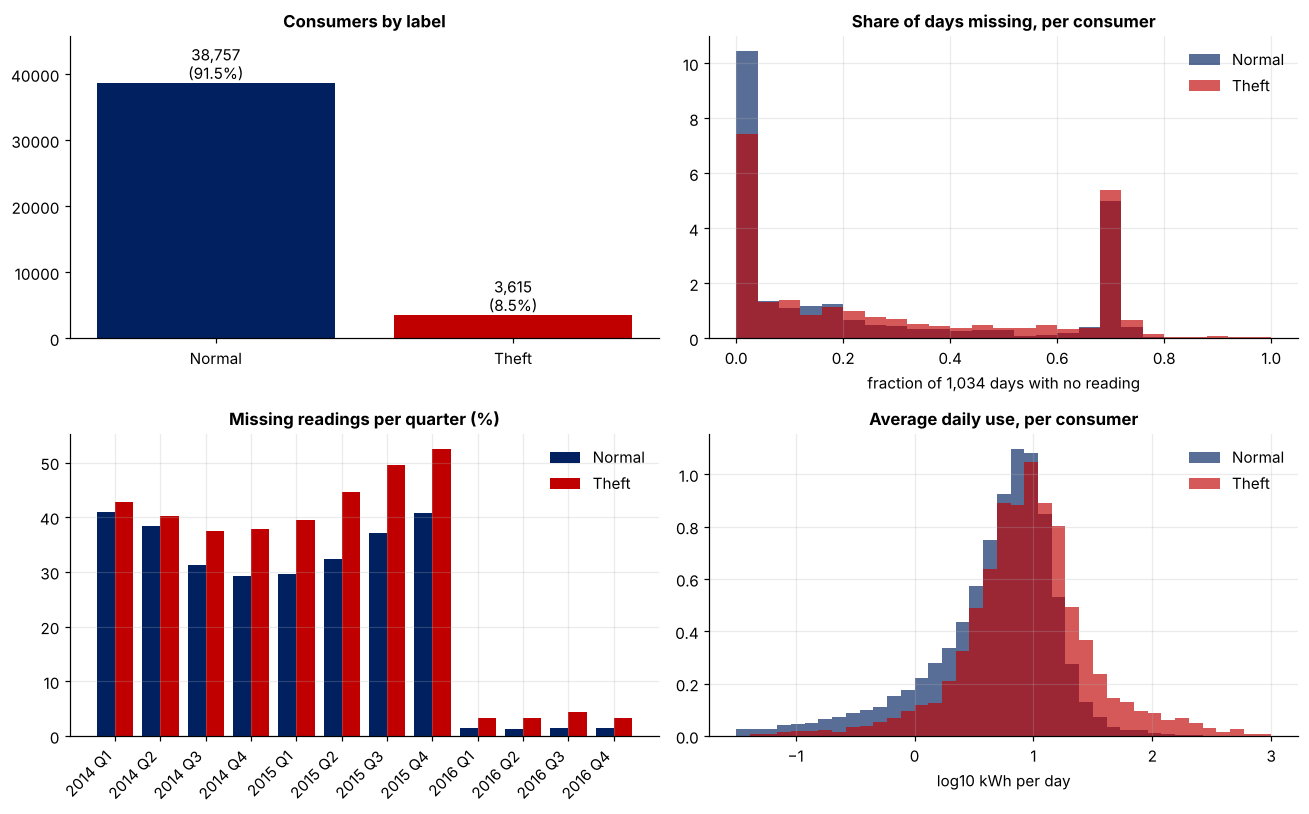

**Findings.** 8.5% of consumers are thieves (about 1 in 12), so accuracy alone is meaningless and we report precision, recall and AUC.
25.6% of all readings are missing, and **thieves are missing more** (31.5% vs 25.1%), so gaps are a signal and are kept as a feature.
Missingness is concentrated in 2014-2015 and almost disappears in 2016. 40% of consumers miss more than 20% of days; dropping them would change the theft share from 8.5% to 6.8%, so we keep them.
2,109 accounts read exactly zero on every day and 5 have no readings at all.

In [3]:
nan_mask = np.isnan(X)
allnan  = nan_mask.all(1)
allzero = (np.nan_to_num(X) == 0).all(1) & ~allnan
miss_pc = nan_mask.mean(1)
y1 = y_all == 1

q = dates.to_period('Q'); quarters = sorted(q.unique())
qmiss = {c: [nan_mask[(y_all == c)][:, (q == k)].mean() * 100 for k in quarters] for c in (0, 1)}
mean_use_raw = np.nanmean(X, axis=1)

fig, ax = plt.subplots(2, 2, figsize=(12, 7.5))
a = ax[0, 0]
cnt = [(y_all == 0).sum(), (y_all == 1).sum()]
a.bar(['Normal', 'Theft'], cnt, color=[NAVY, RED])
for i, v in enumerate(cnt): a.text(i, v, f'{v:,}\n({v / n:.1%})', ha='center', va='bottom')
a.set_title('Consumers by label'); a.set_ylim(0, max(cnt) * 1.18); a.grid(False)

a = ax[0, 1]
bins = np.linspace(0, 1, 26)
a.hist(miss_pc[~y1], bins, color=NAVY, alpha=.65, density=True, label='Normal')
a.hist(miss_pc[y1], bins, color=RED, alpha=.65, density=True, label='Theft')
a.set_title('Share of days missing, per consumer'); a.set_xlabel('fraction of 1,034 days with no reading'); a.legend()

a = ax[1, 0]
w = .4; xx = np.arange(len(quarters))
a.bar(xx - w / 2, qmiss[0], w, color=NAVY, label='Normal'); a.bar(xx + w / 2, qmiss[1], w, color=RED, label='Theft')
a.set_xticks(xx); a.set_xticklabels([str(k).replace('Q', ' Q') for k in quarters], rotation=45, ha='right')
a.set_title('Missing readings per quarter (%)'); a.legend()

a = ax[1, 1]
pos = mean_use_raw > 0
lb = np.linspace(-1.5, 3, 40)
a.hist(np.log10(mean_use_raw[pos & ~y1]), lb, color=NAVY, alpha=.65, density=True, label='Normal')
a.hist(np.log10(mean_use_raw[pos & y1]), lb, color=RED, alpha=.65, density=True, label='Theft')
a.set_title('Average daily use, per consumer'); a.set_xlabel('log10 kWh per day'); a.legend()
fig.tight_layout(); save(fig, 'sgcc_01_balance_missing')

SUMMARY['sgcc'].update(all_zero_accounts=int(allzero.sum()), all_nan_accounts=int(allnan.sum()),
    missing_pct=float(nan_mask.mean() * 100), missing_pct_normal=float(nan_mask[~y1].mean() * 100),
    missing_pct_theft=float(nan_mask[y1].mean() * 100),
    quarters=[str(k) for k in quarters], q_missing_normal=[float(v) for v in qmiss[0]], q_missing_theft=[float(v) for v in qmiss[1]],
    share_over20pct_missing=float((miss_pc > .2).mean() * 100))
drop20 = miss_pc <= .2
SUMMARY['sgcc']['theft_pct_if_drop20'] = float(y_all[drop20].mean() * 100)
say(f'''**Findings.** {y_all.mean():.1%} of consumers are thieves (about 1 in {1 / y_all.mean():.0f}), so accuracy alone is meaningless and we report precision, recall and AUC.
{nan_mask.mean():.1%} of all readings are missing, and **thieves are missing more** ({nan_mask[y1].mean():.1%} vs {nan_mask[~y1].mean():.1%}), so gaps are a signal and are kept as a feature.
Missingness is concentrated in 2014-2015 and almost disappears in 2016. {(miss_pc > .2).mean():.0%} of consumers miss more than 20% of days; dropping them would change the theft share from {y_all.mean():.1%} to {y_all[drop20].mean():.1%}, so we keep them.
{int(allzero.sum()):,} accounts read exactly zero on every day and {int(allnan.sum())} have no readings at all.''')

### 1.2 Cleaning: bad dates, extreme values, empty accounts

Days with the highest network-wide average (x median day):
2014-10-03    57.66
2014-07-11     4.13
2014-10-10     3.96
2014-06-29     3.88
2014-07-10     3.78


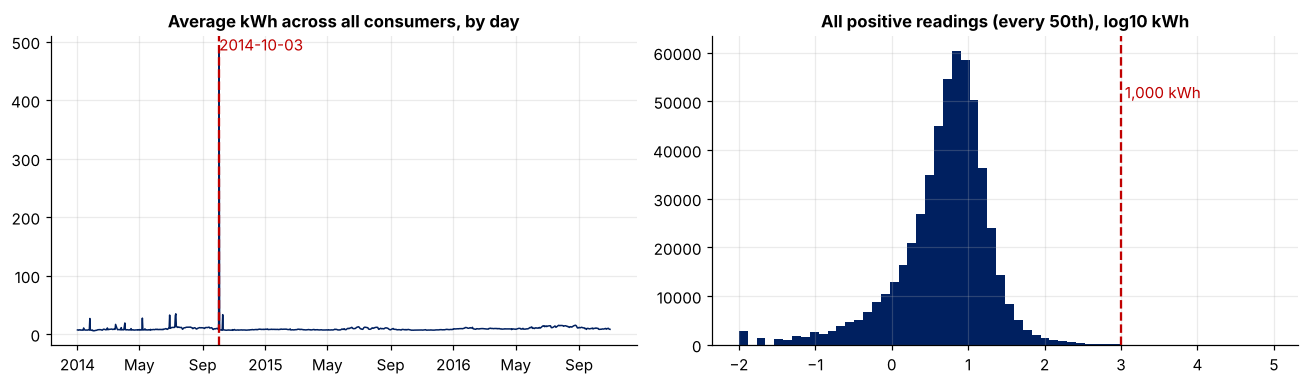

**Cleaning rules.** (1) Columns sorted by date (the file stores them as text in the wrong order). (2) **2014-10-03** averages 58x a normal day, so it is treated as missing. (3) The maximum raw reading is **800,003 kWh in one day**; 8,594 readings exceed 1,000 kWh, so each consumer's top 0.1% is treated as missing. (4) 2,114 empty accounts are dropped.
**40,258 consumers remain (3,579 thieves, 8.9%).**

In [4]:
daily_mean = np.nanmean(X, axis=0)
ratio = daily_mean / np.nanmedian(daily_mean)
top = pd.Series(ratio, index=dates).sort_values(ascending=False).head(5)
spike_idx = int(np.nanargmax(ratio)); spike_date = dates[spike_idx]
print('Days with the highest network-wide average (x median day):')
print(top.round(2).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(dates, daily_mean, color=NAVY, lw=1); ax[0].axvline(spike_date, color=RED, ls='--')
ax[0].set_title('Average kWh across all consumers, by day'); ax[0].annotate(f'{spike_date.date()}', (spike_date, daily_mean[spike_idx]), color=RED)
raw_max = np.nanmax(X); n_huge = int((X > 1000).sum())
cap = np.nanpercentile(X, 99.9, axis=1)
n_capped = int((X > cap[:, None]).sum())
ax[1].hist(np.log10(X[(X > 0)][::50]), 60, color=NAVY); ax[1].set_title('All positive readings (every 50th), log10 kWh')
ax[1].axvline(3, color=RED, ls='--'); ax[1].text(3.05, ax[1].get_ylim()[1] * .8, '1,000 kWh', color=RED)
fig.tight_layout(); save(fig, 'sgcc_02_cleaning')

Xc_full = X.copy()
if ratio[spike_idx] > 3:
    Xc_full[:, spike_idx] = np.nan                         # one-day bad record
Xc_full[Xc_full > cap[:, None]] = np.nan                   # winsorise: top 0.1% per consumer treated as missing
keep = ~(allzero | allnan)
Xc, yc = Xc_full[keep], y_all[keep]
SUMMARY['sgcc'].update(spike_date=str(spike_date.date()), spike_ratio=float(ratio[spike_idx]), raw_max_kwh=float(raw_max),
                       readings_over_1000=n_huge, kept=int(keep.sum()), kept_thieves=int(yc.sum()),
                       kept_theft_pct=float(yc.mean() * 100))
say(f'''**Cleaning rules.** (1) Columns sorted by date (the file stores them as text in the wrong order). (2) **{spike_date.date()}** averages {ratio[spike_idx]:.0f}x a normal day, so it is treated as missing. (3) The maximum raw reading is **{raw_max:,.0f} kWh in one day**; {n_huge:,} readings exceed 1,000 kWh, so each consumer's top 0.1% is treated as missing. (4) {int((~keep).sum()):,} empty accounts are dropped.
**{keep.sum():,} consumers remain ({yc.sum():,} thieves, {yc.mean():.1%}).**''')

### 1.3 What does theft look like? Usage over time

If thieves simply cut their consumption, a "sudden drop" detector would work. Here is what the data shows.

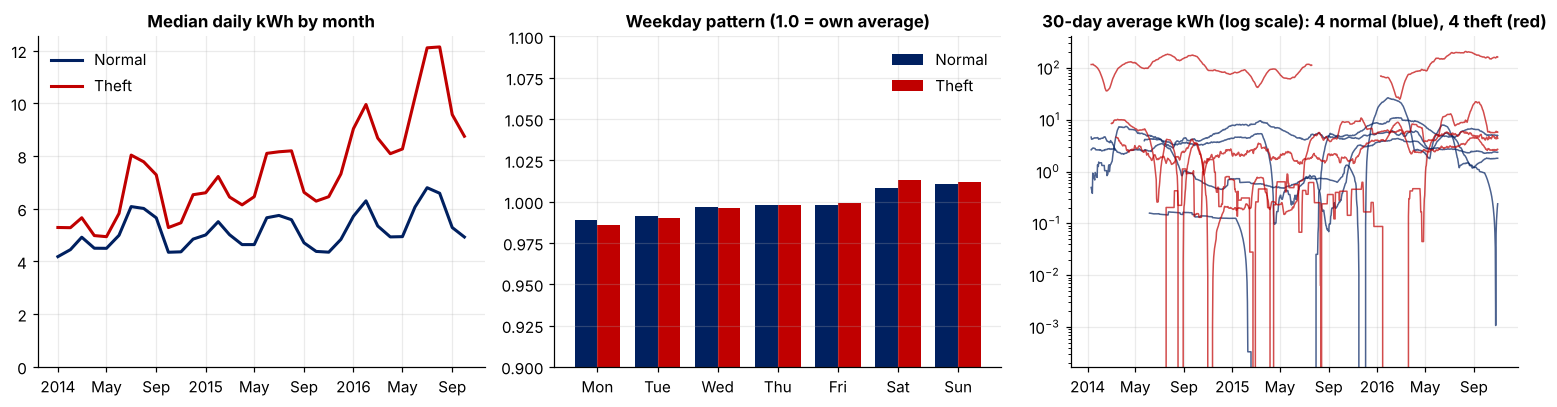

**Findings.** The typical thief uses **more** electricity than the typical normal consumer in every month, and the gap grows: usage rose +53% from year 1 to year 3 for thieves vs +12% for normal consumers.
The meter of a confirmed thief does not show an obvious drop, so a drop detector alone cannot work on SGCC. Usage is also seasonal (highest in calendar month 7), which affects every consumer, so any rule must be season-aware.

In [5]:
nc = Xc.shape[0]
nan_c = np.isnan(Xc)
month_id = ((dates.year - dates.year.min()) * 12 + dates.month - 1).values
months = np.unique(month_id); n_m = len(months)
mm = np.stack([np.nanmean(Xc[:, month_id == m], axis=1) for m in months], axis=1)       # consumer x month
month_dates = pd.to_datetime([f'{dates.year.min() + m // 12}-{m % 12 + 1:02d}-01' for m in months])
dow = dates.dayofweek.values
wk = np.stack([np.nanmean(Xc[:, dow == k], axis=1) for k in range(7)], axis=1)

med_by_class = {c: np.nanmedian(mm[yc == c], axis=0) for c in (0, 1)}
growth_cls = {c: np.nanmean(med_by_class[c][-12:]) / np.nanmean(med_by_class[c][:12]) - 1 for c in (0, 1)}
cal_month = month_dates.month.values
seas = pd.Series(np.nanmean(mm, axis=0)).groupby(cal_month).mean()
SEAS = {'SGCC (China)': (seas / seas.mean()).values}

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].plot(month_dates, med_by_class[0], color=NAVY, lw=2, label='Normal'); ax[0].plot(month_dates, med_by_class[1], color=RED, lw=2, label='Theft')
ax[0].set_title('Median daily kWh by month'); ax[0].set_ylim(0); ax[0].legend()
wk_rel = wk / np.nanmean(wk, axis=1, keepdims=True)
for c, col, lab in ((0, NAVY, 'Normal'), (1, RED, 'Theft')):
    ax[1].bar(np.arange(7) + (c - .5) * .38, np.nanmedian(wk_rel[yc == c], axis=0) , .38, color=col, label=lab)
ax[1].set_xticks(range(7)); ax[1].set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']); ax[1].set_ylim(.9, 1.1)
ax[1].set_title('Weekday pattern (1.0 = own average)'); ax[1].legend()
rng = np.random.default_rng(0)
for c, col in ((0, NAVY), (1, RED)):
    for i in rng.choice(np.where((yc == c) & (nan_c.mean(1) < .2))[0], 4, replace=False):
        ax[2].plot(dates, pd.Series(Xc[i]).rolling(30, min_periods=10).mean().values, color=col, alpha=.7, lw=1)
ax[2].set_title('30-day average kWh (log scale): 4 normal (blue), 4 theft (red)'); ax[2].set_yscale('log')
fig.tight_layout(); save(fig, 'sgcc_03_usage_over_time')

SUMMARY['sgcc'].update(growth_normal_pct=float(growth_cls[0] * 100), growth_theft_pct=float(growth_cls[1] * 100),
    months=[d.strftime('%b %y') for d in month_dates], monthly_median_normal=[float(v) for v in med_by_class[0]],
    monthly_median_theft=[float(v) for v in med_by_class[1]])
say(f'''**Findings.** The typical thief uses **more** electricity than the typical normal consumer in every month, and the gap grows: usage rose {growth_cls[1]:+.0%} from year 1 to year 3 for thieves vs {growth_cls[0]:+.0%} for normal consumers.
The meter of a confirmed thief does not show an obvious drop, so a drop detector alone cannot work on SGCC. Usage is also seasonal (highest in calendar month {int(seas.idxmax())}), which affects every consumer, so any rule must be season-aware.''')

### 1.4 Fourteen behavioural features and how well each separates thieves

AUC 0.5 = coin toss, 1.0 = perfect. Each feature is scored alone, then all 14 are combined in one gradient-boosted model with 5-fold cross-validation (split by consumer).

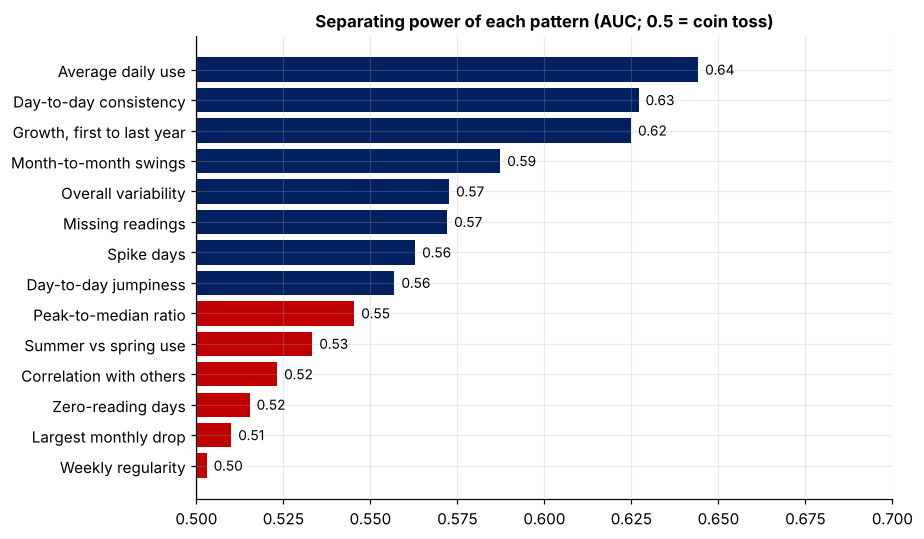

,auc_raw,AUC,thieves have
Average daily use,0.644,0.644,higher
Day-to-day consistency,0.373,0.627,lower
"Growth, first to last year",0.625,0.625,higher
Month-to-month swings,0.587,0.587,higher
Overall variability,0.573,0.573,higher
Missing readings,0.572,0.572,higher
Spike days,0.563,0.563,higher
Day-to-day jumpiness,0.443,0.557,lower
Peak-to-median ratio,0.545,0.545,higher
Summer vs spring use,0.533,0.533,higher


In [6]:
eps = 1e-6
obs = (~nan_c).sum(1).clip(min=1)
mean_use = np.nanmean(Xc, 1)
med = np.nanmedian(Xc, 1)
std = np.nanstd(Xc, 1)
F = pd.DataFrame({
    'Average daily use':        mean_use,
    'Overall variability':      std / (mean_use + eps),
    'Day-to-day jumpiness':     np.nanmean(np.abs(np.diff(Xc, axis=1)), 1) / (mean_use + eps),
    'Day-to-day consistency':   (((Xc >= .5 * med[:, None]) & (Xc <= 1.5 * med[:, None])) & ~nan_c).sum(1) / obs,
    'Weekly regularity':        np.nanstd(wk, 1) / (np.nanmean(wk, 1) + eps),
    'Growth, first to last year': np.nanmean(mm[:, -12:], 1) / (np.nanmean(mm[:, :12], 1) + eps),
    'Month-to-month swings':    np.nanstd(mm, 1) / (np.nanmean(mm, 1) + eps),
    'Missing readings':         nan_c.mean(1),
    'Spike days':               ((Xc > 3 * med[:, None]) & ~nan_c).sum(1) / obs,
    'Peak-to-median ratio':     np.nanmax(Xc, 1) / (med + eps),
    'Zero-reading days':        ((Xc == 0) & ~nan_c).sum(1) / obs,
    'Largest monthly drop':     np.nanmax(np.where(mm[:, :-1] > 0, 1 - mm[:, 1:] / np.where(mm[:, :-1] > 0, mm[:, :-1], 1), np.nan), 1),
    'Summer vs spring use':     np.nanmean(mm[:, np.isin(cal_month, [6, 7, 8])], 1) / (np.nanmean(mm[:, np.isin(cal_month, [3, 4, 5])], 1) + eps),
})
peer = np.nanmedian(mm, axis=0)
mmf = np.where(np.isnan(mm), np.nanmean(mm, 1, keepdims=True), mm)
z = (mmf - mmf.mean(1, keepdims=True)) / (mmf.std(1, keepdims=True) + eps)
F['Correlation with others'] = (z * ((peer - peer.mean()) / peer.std())).mean(1)
F = F.replace([np.inf, -np.inf], np.nan)

res = pd.DataFrame({'auc_raw': {c: auc(yc, F[c]) for c in F}})
res['AUC'] = res.auc_raw.where(res.auc_raw >= .5, 1 - res.auc_raw)
res['thieves have'] = np.where(res.auc_raw >= .5, 'higher', 'lower')
res = res.sort_values('AUC', ascending=False)

try:
    from sklearn.ensemble import HistGradientBoostingClassifier
    from sklearn.model_selection import StratifiedKFold, cross_val_predict
    skf = StratifiedKFold(5, shuffle=True, random_state=0)
    clf = HistGradientBoostingClassifier(max_iter=200, learning_rate=.06, random_state=0)
    oof = cross_val_predict(clf, F.values, yc, cv=skf, method='predict_proba')[:, 1]
    comb_auc = auc(yc, oof)
    top100 = int(yc[np.argsort(-oof)[:100]].sum()); top1000 = int(yc[np.argsort(-oof)[:1000]].sum())
except ImportError:
    comb_auc = top100 = top1000 = None; print('scikit-learn not installed: skipping the combined model')

fig, ax = plt.subplots(figsize=(8.5, 5))
r_ = res.iloc[::-1]
ax.barh(r_.index, r_.AUC, color=[RED if v < .55 else NAVY for v in r_.AUC]); ax.set_xlim(.5, max(.7, r_.AUC.max() + .03))
for i, v in enumerate(r_.AUC): ax.text(v + .002, i, f'{v:.2f}', va='center', fontsize=9)
ax.axvline(.5, color=GREY); ax.set_title('Separating power of each pattern (AUC; 0.5 = coin toss)')
fig.tight_layout(); save(fig, 'sgcc_04_feature_auc')

SUMMARY['sgcc'].update(feature_auc={k: float(v) for k, v in res.AUC.items()}, combined_auc=comb_auc,
                       top100_hits=top100, top1000_hits=top1000, scored_consumers=int(len(yc)),
                       random_top100=float(100 * yc.mean()))
res.round(3)

In [7]:
say(f'''**Findings.** Best single patterns: **{res.index[0]}** ({res.AUC.iloc[0]:.2f}), **{res.index[1]}** ({res.AUC.iloc[1]:.2f}), **{res.index[2]}** ({res.AUC.iloc[2]:.2f}). The "largest monthly drop" is {res.loc['Largest monthly drop', 'AUC']:.2f}, essentially a coin toss.
Combined in one model: **AUC {comb_auc:.2f}** (cross-validated, offline, whole-period features). Among the 100 consumers ranked most suspicious, **{top100} are real thieves** (random choice would give about {100 * yc.mean():.0f}); among the top 1,000, {top1000}.
This is our baseline. A streaming version only sees past data, so it will score somewhat lower; the published SGCC benchmark (Zheng et al., 2018) is about 0.79.''' if comb_auc else 'Install scikit-learn to see the combined model.')

**Findings.** Best single patterns: **Average daily use** (0.64), **Day-to-day consistency** (0.63), **Growth, first to last year** (0.62). The "largest monthly drop" is 0.51, essentially a coin toss.
Combined in one model: **AUC 0.79** (cross-validated, offline, whole-period features). Among the 100 consumers ranked most suspicious, **89 are real thieves** (random choice would give about 9); among the top 1,000, 608.
This is our baseline. A streaming version only sees past data, so it will score somewhat lower; the published SGCC benchmark (Zheng et al., 2018) is about 0.79.

---
# 2. STEG (Tunisian electricity and gas company)

Two tables: **clients** (one label each, from field inspections) and **invoices** (one row per billing period, read from conventional meters, so roughly every few months rather than every day). Electricity and gas share one file; `counter_type` tells them apart.

In [8]:
ct  = pd.read_csv(DATA / 'client_train.csv').rename(columns={'disrict': 'district'})
cte = pd.read_csv(DATA / 'client_test.csv').rename(columns={'disrict': 'district'})
for t in (ct, cte):
    t['creation_date'] = pd.to_datetime(t['creation_date'], dayfirst=True, errors='coerce')
    t['create_year'] = t.creation_date.dt.year

inv = pd.read_csv(DATA / 'invoice_train.csv', parse_dates=['invoice_date'],
                  dtype={'client_id': 'category', 'counter_statue': 'category', 'counter_type': 'category'})
inv_te = pd.read_csv(DATA / 'invoice_test.csv', usecols=['client_id', 'invoice_date', 'counter_type'])
for c in inv.select_dtypes('int64').columns:
    if c != 'counter_number': inv[c] = pd.to_numeric(inv[c], downcast='integer')
inv['total'] = inv[['consommation_level_1', 'consommation_level_2', 'consommation_level_3', 'consommation_level_4']].sum(axis=1)

n_cl, n_fraud = len(ct), int(ct.target.sum())
SUMMARY['steg'] = dict(clients_train=n_cl, clients_test=len(cte), fraud=n_fraud, fraud_pct=float(n_fraud / n_cl * 100),
                       ratio=float((n_cl - n_fraud) / n_fraud), invoices_train=len(inv), invoices_test=len(inv_te),
                       invoice_first=str(inv.invoice_date.min().date()), invoice_last=str(inv.invoice_date.max().date()),
                       clients_with_invoices=int(inv.client_id.nunique()),
                       elec_pct=float((inv.counter_type == 'ELEC').mean() * 100))
pd.Series({'train clients': f'{n_cl:,}', 'test clients (no labels)': f'{len(cte):,}', 'fraud clients (train)': f'{n_fraud:,} ({n_fraud / n_cl:.1%})',
           'normal : fraud': f"{SUMMARY['steg']['ratio']:.1f} : 1", 'train invoices': f'{len(inv):,}', 'test invoices': f'{len(inv_te):,}',
           'invoice dates': f"{inv.invoice_date.min().date()} to {inv.invoice_date.max().date()}",
           'electricity share of invoices': f"{SUMMARY['steg']['elec_pct']:.0f}%",
           'train clients with no invoice': int(n_cl - inv.client_id.nunique())}).to_frame('value')

,value
train clients,"135,493"
test clients (no labels),"58,069"
fraud clients (train),"7,566 (5.6%)"
normal : fraud,16.9 : 1
train invoices,"4,476,749"
test invoices,"1,939,730"
invoice dates,1977-06-09 to 2019-12-07
electricity share of invoices,69%
train clients with no invoice,0


### 2.1 Who commits fraud? Category, region and tenure

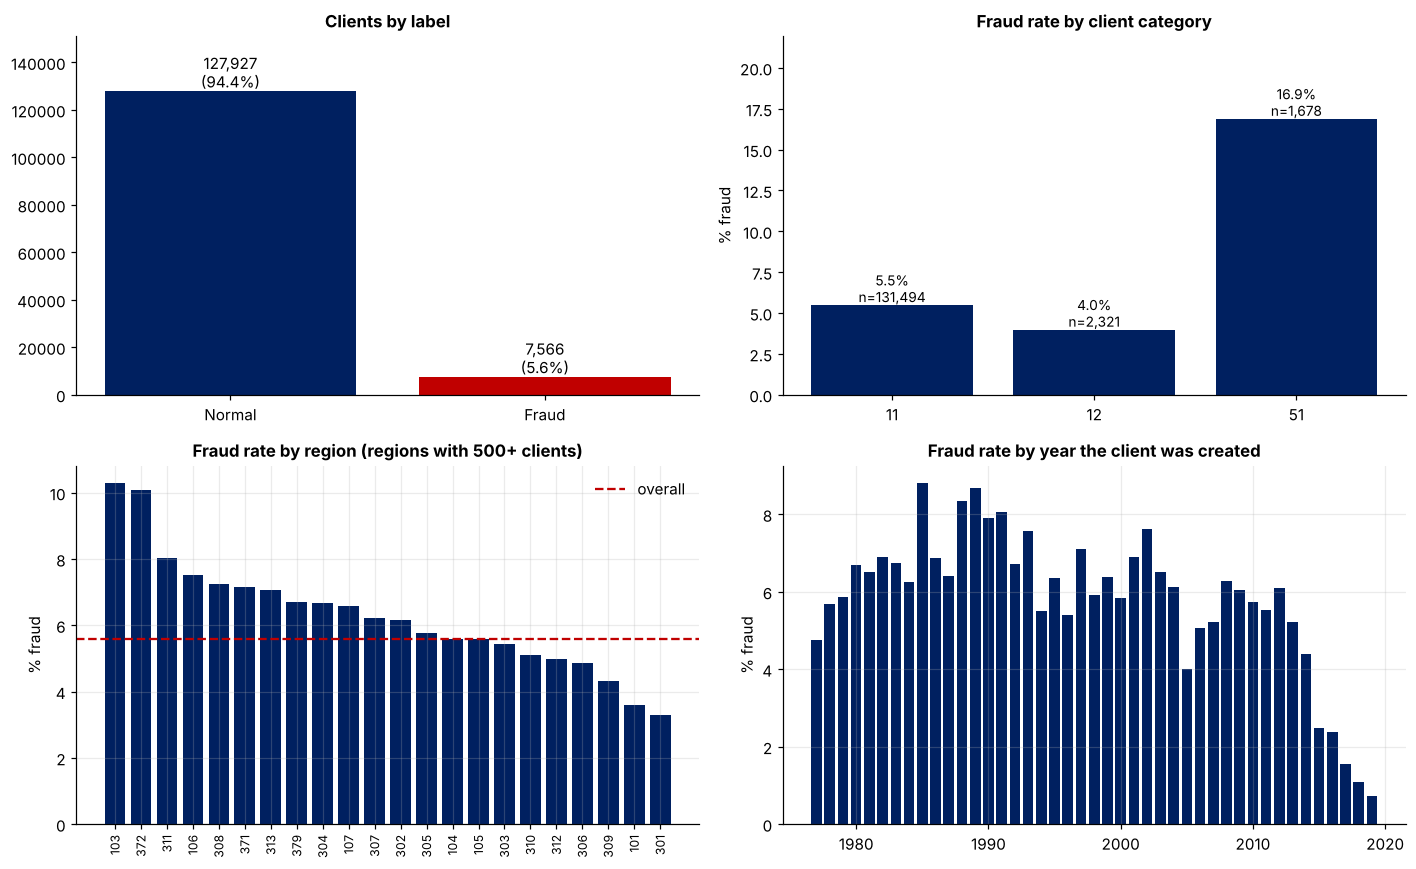

**Findings.** 5.6% of clients are flagged (about 1 in 18). Fraud is far from uniform: by category it ranges from 4.0% to 16.9%, and by region from 3.3% to 10.3%. Category and region are useful context for the agent but are not "behaviour".

In [9]:
fr_cat = ct.groupby('client_catg').target.agg(['mean', 'size'])
fr_reg = ct.groupby('region').target.agg(['mean', 'size']); fr_reg = fr_reg[fr_reg['size'] >= 500].sort_values('mean', ascending=False)
fr_yr = ct.groupby('create_year').target.agg(['mean', 'size']); fr_yr = fr_yr[fr_yr['size'] >= 200]
inv_yr = inv.assign(year=inv.invoice_date.dt.year).groupby(['year', 'counter_type']).size().unstack(fill_value=0)
inv_yr = inv_yr[inv_yr.index >= 2005]

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
a = ax[0, 0]; cnts = [(ct.target == 0).sum(), (ct.target == 1).sum()]
a.bar(['Normal', 'Fraud'], cnts, color=[NAVY, RED]); a.grid(False)
for i, v in enumerate(cnts): a.text(i, v, f'{v:,}\n({v / n_cl:.1%})', ha='center', va='bottom')
a.set_ylim(0, max(cnts) * 1.18); a.set_title('Clients by label')
a = ax[0, 1]
a.bar(fr_cat.index.astype(str), fr_cat['mean'] * 100, color=NAVY)
for i, (m, s) in enumerate(zip(fr_cat['mean'], fr_cat['size'])): a.text(i, m * 100, f'{m:.1%}\nn={s:,}', ha='center', va='bottom', fontsize=9)
a.set_title('Fraud rate by client category'); a.set_ylabel('% fraud'); a.set_ylim(0, fr_cat['mean'].max() * 100 * 1.3); a.grid(False)
a = ax[1, 0]
a.bar(range(len(fr_reg)), fr_reg['mean'] * 100, color=NAVY); a.set_xticks(range(len(fr_reg))); a.set_xticklabels(fr_reg.index.astype(str), rotation=90, fontsize=8); a.axhline(ct.target.mean() * 100, color=RED, ls='--', label='overall')
a.set_title('Fraud rate by region (regions with 500+ clients)'); a.set_ylabel('% fraud'); a.legend()
a = ax[1, 1]
a.bar(fr_yr.index.astype(int), fr_yr['mean'] * 100, color=NAVY); a.set_title('Fraud rate by year the client was created'); a.set_ylabel('% fraud')
fig.tight_layout(); save(fig, 'steg_01_labels')

SUMMARY['steg'].update(fraud_by_catg={str(k): float(v) for k, v in fr_cat['mean'].items()},
    clients_by_catg={str(k): int(v) for k, v in fr_cat['size'].items()},
    region_fraud_min=float(fr_reg['mean'].min() * 100), region_fraud_max=float(fr_reg['mean'].max() * 100))
say(f'''**Findings.** {n_fraud / n_cl:.1%} of clients are flagged (about 1 in {n_cl / n_fraud:.0f}). Fraud is far from uniform: by category it ranges from {fr_cat['mean'].min():.1%} to {fr_cat['mean'].max():.1%}, and by region from {fr_reg['mean'].min():.1%} to {fr_reg['mean'].max():.1%}. Category and region are useful context for the agent but are not "behaviour".''')

### 2.2 Billing history: sparse, irregular, and mostly electricity

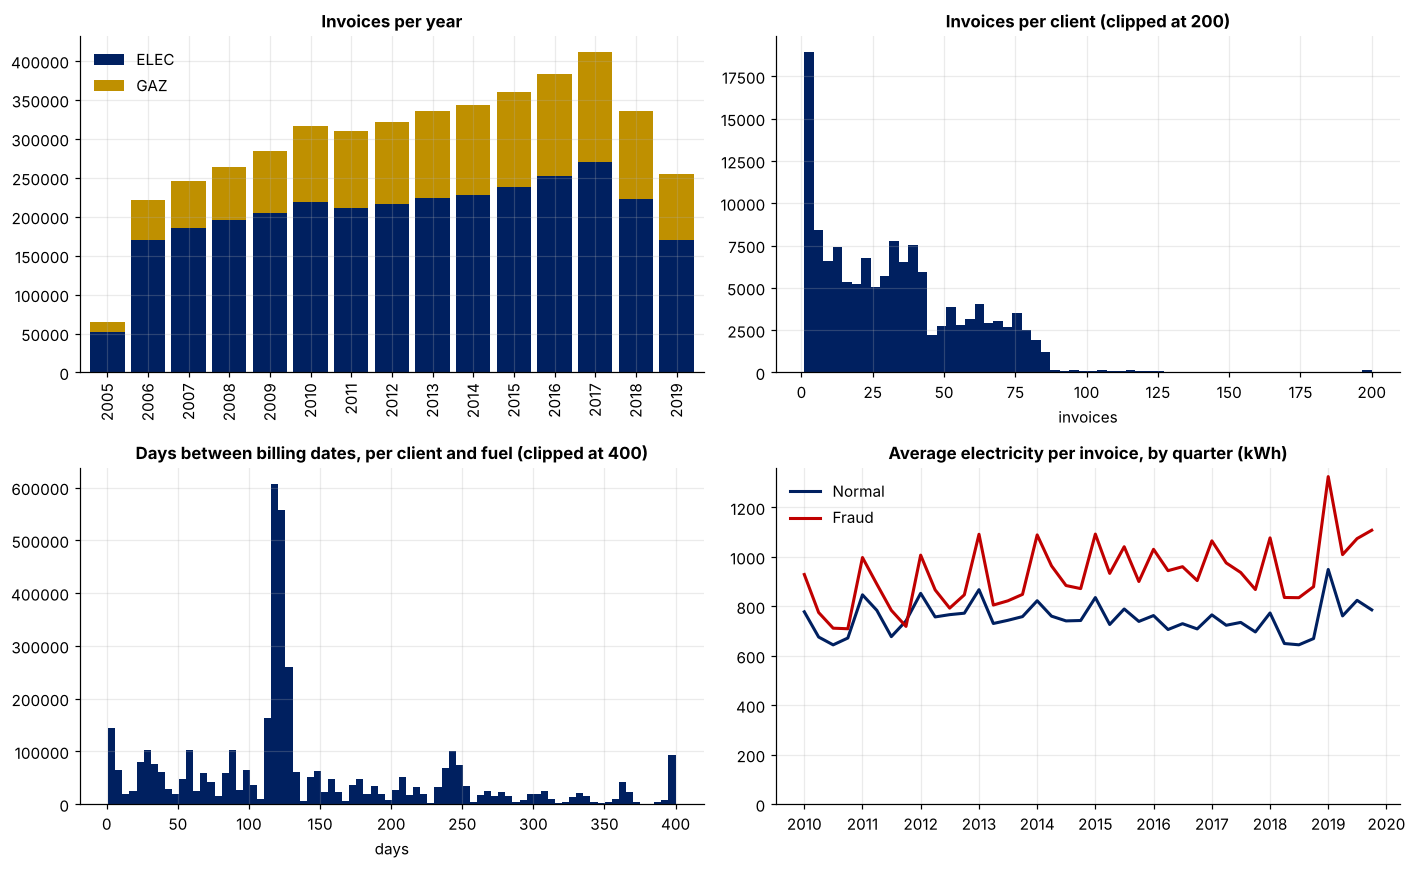

**Findings.** Clients have a median of **30 invoices**, a median **121 days** apart, which is far too sparse for real-time detection. STEG is therefore our second **accuracy** benchmark (who is committing fraud), never a speed benchmark.
10.4% of invoices show zero consumption. The largest single invoice is 999,910, so heavy tails need capping.

In [10]:
per_client = inv.groupby('client_id', observed=True).size()
dd = inv[['client_id', 'counter_type', 'invoice_date']].drop_duplicates().sort_values(['client_id', 'counter_type', 'invoice_date'])
gap = dd.groupby(['client_id', 'counter_type'], observed=True).invoice_date.diff().dt.days.dropna()   # per client and fuel, distinct billing dates
elec = inv[inv.counter_type == 'ELEC']
tot_cap = elec.total.quantile(.999)
codes = inv.client_id.cat.codes.values
tg = ct.set_index('client_id').target.reindex(inv.client_id.cat.categories).values
inv['target'] = tg[codes]

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
a = ax[0, 0]; inv_yr.plot.bar(stacked=True, ax=a, color=[NAVY, GOLD], width=.85); a.set_title('Invoices per year'); a.set_xlabel('')
a.legend(title='')
a = ax[0, 1]; a.hist(per_client.clip(upper=200), 60, color=NAVY); a.set_title('Invoices per client (clipped at 200)'); a.set_xlabel('invoices')
a = ax[1, 0]; a.hist(gap.clip(upper=400), 80, color=NAVY); a.set_title('Days between billing dates, per client and fuel (clipped at 400)'); a.set_xlabel('days')
a = ax[1, 1]
sub = inv[(inv.counter_type == 'ELEC') & (inv.invoice_date >= '2010-01-01') & (inv.total >= 0) & (inv.total < tot_cap) & inv.target.notna()]
mm_ = sub.groupby([sub.invoice_date.dt.to_period('Q').dt.to_timestamp(), 'target']).total.mean().unstack()
a.plot(mm_.index, mm_[0.0], color=NAVY, lw=2, label='Normal'); a.plot(mm_.index, mm_[1.0], color=RED, lw=2, label='Fraud')
a.set_title('Average electricity per invoice, by quarter (kWh)'); a.legend(); a.set_ylim(0)
fig.tight_layout(); save(fig, 'steg_02_invoices')

neg = int((inv.total < 0).sum()); zero_sh = float((inv.total == 0).mean())
SUMMARY['steg'].update(median_invoices_per_client=float(per_client.median()), median_gap_days=float(gap.median()),
                       zero_invoice_pct=zero_sh * 100, negative_invoices=neg, max_total=float(inv.total.max()),
                       invoice_years=[int(v) for v in inv_yr.index], inv_elec=[int(v) for v in inv_yr['ELEC']], inv_gaz=[int(v) for v in inv_yr['GAZ']],
                       q_labels=[f'{d.year} Q{(d.month - 1) // 3 + 1}' for d in mm_.index],
                       q_normal=[float(v) for v in mm_[0.0]], q_fraud=[float(v) for v in mm_[1.0]])
say(f'''**Findings.** Clients have a median of **{per_client.median():.0f} invoices**, a median **{gap.median():.0f} days** apart, which is far too sparse for real-time detection. STEG is therefore our second **accuracy** benchmark (who is committing fraud), never a speed benchmark.
{zero_sh:.1%} of invoices show zero consumption{(' and ' + format(neg, ',') + ' show negative consumption') if neg else ''}. The largest single invoice is {inv.total.max():,.0f}, so heavy tails need capping.''')

### 2.3 Client-level features and what separates fraud clients

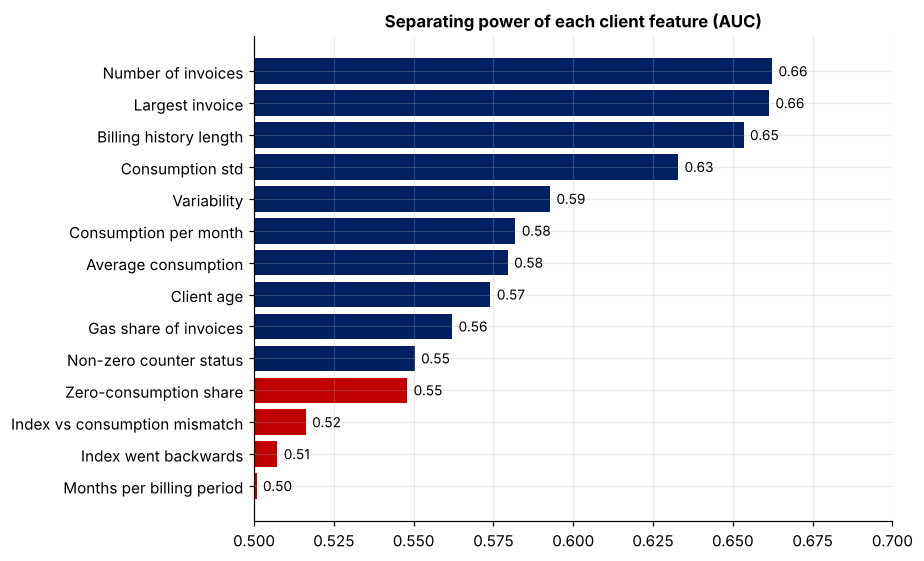

**Findings.** Strongest single features: **Number of invoices** (0.66), **Largest invoice** (0.66), **Billing history length** (0.65).
Combined: **AUC 0.77** with all features, **0.75** with behaviour only (no category/region/district). Top-100 ranked clients contain **38 fraud cases** (random: about 6).

,auc_raw,AUC
Number of invoices,0.662,0.662
Largest invoice,0.661,0.661
Billing history length,0.653,0.653
Consumption std,0.633,0.633
Variability,0.593,0.593
Consumption per month,0.582,0.582
Average consumption,0.579,0.579
Client age,0.574,0.574
Gas share of invoices,0.562,0.562
Non-zero counter status,0.550,0.550


In [11]:
inv['zero'] = inv.total == 0
inv['months'] = inv.months_number.clip(lower=1)
inv['cpm'] = inv.total / inv.months
inv['idx_diff'] = inv.new_index.astype('int64') - inv.old_index.astype('int64')
inv['neg_idx'] = inv.idx_diff < 0
inv['mismatch'] = (inv.idx_diff - inv.total).abs() > 0
inv['gaz'] = inv.counter_type == 'GAZ'
inv['odd_status'] = inv.counter_statue.astype(str) != '0'
g = inv.groupby('client_id', observed=True)
A = g.agg(n_inv=('total', 'size'), mean_total=('total', 'mean'), std_total=('total', 'std'), max_total=('total', 'max'),
          zero_share=('zero', 'mean'), mean_cpm=('cpm', 'mean'), neg_idx_share=('neg_idx', 'mean'),
          index_mismatch_share=('mismatch', 'mean'), gas_share=('gaz', 'mean'), odd_status_share=('odd_status', 'mean'),
          mean_months=('months', 'mean'), first=('invoice_date', 'min'), last=('invoice_date', 'max'))
A['variability'] = A.std_total / (A.mean_total.abs() + 1e-6)
A['history_days'] = (A['last'] - A['first']).dt.days
A = A.drop(columns=['first', 'last']); A.index = A.index.astype(str)
D = ct.set_index('client_id').join(A)
D['client_age_years'] = (pd.Timestamp('2019-12-31') - D.creation_date).dt.days / 365.25
feat_cols = list(A.columns) + ['client_age_years', 'client_catg', 'region', 'district']
nice = {'n_inv': 'Number of invoices', 'mean_total': 'Average consumption', 'std_total': 'Consumption std', 'max_total': 'Largest invoice',
        'zero_share': 'Zero-consumption share', 'mean_cpm': 'Consumption per month', 'neg_idx_share': 'Index went backwards',
        'index_mismatch_share': 'Index vs consumption mismatch', 'gas_share': 'Gas share of invoices', 'odd_status_share': 'Non-zero counter status',
        'mean_months': 'Months per billing period', 'variability': 'Variability', 'history_days': 'Billing history length',
        'client_age_years': 'Client age', 'client_catg': 'Client category', 'region': 'Region', 'district': 'District'}
Dl = D[D.target.notna() & D.n_inv.notna()]
single_cols = [c for c in feat_cols if c not in ('client_catg', 'region', 'district')]   # category codes are labels, not ordered numbers
res2 = pd.DataFrame({'auc_raw': {c: auc(Dl.target, Dl[c]) for c in single_cols}})
res2['AUC'] = res2.auc_raw.where(res2.auc_raw >= .5, 1 - res2.auc_raw)
res2 = res2.sort_values('AUC', ascending=False)
try:
    from sklearn.ensemble import HistGradientBoostingClassifier
    from sklearn.model_selection import StratifiedKFold, cross_val_predict
    skf = StratifiedKFold(5, shuffle=True, random_state=0)
    oof2 = cross_val_predict(HistGradientBoostingClassifier(max_iter=200, learning_rate=.06, random_state=0),
                             Dl[feat_cols].values, Dl.target.values, cv=skf, method='predict_proba')[:, 1]
    comb2 = auc(Dl.target.values, oof2)
    beh_cols = [c for c in feat_cols if c not in ('client_catg', 'region', 'district')]
    oof2b = cross_val_predict(HistGradientBoostingClassifier(max_iter=200, learning_rate=.06, random_state=0),
                              Dl[beh_cols].values, Dl.target.values, cv=skf, method='predict_proba')[:, 1]
    comb2b = auc(Dl.target.values, oof2b)
    top100_2 = int(Dl.target.values[np.argsort(-oof2)[:100]].sum())
except ImportError:
    comb2 = comb2b = top100_2 = None

fig, ax = plt.subplots(figsize=(8.5, 5.2)); r_ = res2.iloc[::-1]
ax.barh([nice[i] for i in r_.index], r_.AUC, color=[RED if v < .55 else NAVY for v in r_.AUC]); ax.set_xlim(.5, max(.7, r_.AUC.max() + .03))
for i, v in enumerate(r_.AUC): ax.text(v + .002, i, f'{v:.2f}', va='center', fontsize=9)
ax.set_title('Separating power of each client feature (AUC)'); fig.tight_layout(); save(fig, 'steg_03_feature_auc')

SUMMARY['steg'].update(feature_auc={nice[k]: float(v) for k, v in res2.AUC.items()}, combined_auc=comb2, combined_auc_behaviour_only=comb2b,
                       top100_hits=top100_2, scored_clients=int(len(Dl)))
say(f'''**Findings.** Strongest single features: **{nice[res2.index[0]]}** ({res2.AUC.iloc[0]:.2f}), **{nice[res2.index[1]]}** ({res2.AUC.iloc[1]:.2f}), **{nice[res2.index[2]]}** ({res2.AUC.iloc[2]:.2f}).
Combined: **AUC {comb2:.2f}** with all features, **{comb2b:.2f}** with behaviour only (no category/region/district). Top-100 ranked clients contain **{top100_2} fraud cases** (random: about {100 * Dl.target.mean():.0f}).''' if comb2 else 'Install scikit-learn for the combined model.')
res2.rename(index=nice).round(3)

---
# 3. CEEW smart meters: Mathura and Bareilly (India)

About 80 Indian households, one reading **every 3 minutes** with kWh, voltage, current and frequency. There are **no theft labels**: this is the dataset where we *inject* theft at known start times and measure how fast the system notices (Mode B).

Files used: raw 2019-2020 for Mathura, raw 2020-2021 for Bareilly, plus the "SM Cleaned Data" files that fill the remaining periods (Bareilly 2019, Mathura 2021).

In [12]:
# PREP-DEFS
CEEW_FILES = [('Mathura',  'CEEW - Smart meter data Mathura 2019.csv'),
              ('Mathura',  'CEEW - Smart meter data Mathura 2020.csv'),
              ('Mathura',  'SM Cleaned Data MH2021.csv'),
              ('Bareilly', 'SM Cleaned Data BR2019.csv'),
              ('Bareilly', 'CEEW - Smart meter data Bareilly 2020.csv'),
              ('Bareilly', 'CEEW - Smart meter data Bareilly 2021.csv')]
V_LOW, V_HIGH = 207, 253        # -10% / +10% around the 230 V nominal supply

def ceew_profile(city, fn):
    cache = CACHE / f'ceew2_{Path(fn).stem}.pkl'
    if cache.exists():
        return pd.read_pickle(cache)
    t0 = time.time()
    df = pd.read_csv(DATA / fn, parse_dates=['x_Timestamp'],
                     dtype={'t_kWh': 'float32', 'z_Avg Voltage (Volt)': 'float32', 'z_Avg Current (Amp)': 'float32',
                            'y_Freq (Hz)': 'float32', 'meter': 'category'})
    df.columns = ['ts', 'kwh', 'volt', 'amp', 'freq', 'meter']
    df = df.sort_values(['meter', 'ts'], kind='stable').reset_index(drop=True)
    df['date'] = df.ts.dt.normalize(); df['hour'] = df.ts.dt.hour.astype('int8')
    df['outage'] = df.volt <= 10                      # meter is logging but there is no supply voltage
    df['volt_ok'] = df.volt.where(~df.outage)         # voltage statistics use supply-on readings only
    df['na'] = df.kwh.isna(); df['zero'] = df.kwh == 0; df['lowv'] = df.volt_ok < V_LOW; df['highv'] = df.volt_ok > V_HIGH
    df['dt'] = df.groupby('meter', observed=True).ts.diff().dt.total_seconds()
    daily = df.groupby(['meter', 'date'], observed=True).agg(
        kwh=('kwh', 'sum'), n=('kwh', 'size'), na=('na', 'sum'), zero=('zero', 'sum'), outage=('outage', 'sum'), v_mean=('volt_ok', 'mean'),
        v_min=('volt_ok', 'min'), v_max=('volt_ok', 'max'), lowv=('lowv', 'sum'), highv=('highv', 'sum'), amp_max=('amp', 'max'),
        f_min=('freq', 'min'), f_max=('freq', 'max'), kwh_peak=('kwh', 'max')).reset_index()
    daily['city'] = city
    hh = df.groupby(['meter', 'date', 'hour'], observed=True).agg(kwh=('kwh', 'sum'), v=('volt_ok', 'mean'), out=('outage', 'mean')).reset_index()
    hh['weekend'] = hh.date.dt.dayofweek >= 5
    hourly = hh.groupby(['meter', 'weekend', 'hour'], observed=True)[['kwh', 'v', 'out']].mean().reset_index(); hourly['city'] = city
    gaps = df.groupby('meter', observed=True).agg(rows=('kwh', 'size'), first=('ts', 'min'), last=('ts', 'max'), med_dt=('dt', 'median')).reset_index()
    gaps['city'] = city; gaps['file'] = fn
    out = {'daily': daily, 'hourly': hourly, 'gaps': gaps}
    pd.to_pickle(out, cache); print(f'{fn}: {len(df):,} rows in {time.time() - t0:.0f}s'); del df, hh; gc.collect()
    return out

In [13]:
parts = [ceew_profile(c, f) for c, f in CEEW_FILES]
daily = pd.concat([p['daily'] for p in parts], ignore_index=True)
hourly = pd.concat([p['hourly'] for p in parts], ignore_index=True)
gaps = pd.concat([p['gaps'] for p in parts], ignore_index=True)
daily['meter'] = daily.meter.astype(str)
daily['full'] = daily.n >= 456                    # at least 95% of the 480 readings in a day
tot_rows = int(gaps.rows.sum())
meters = daily.groupby(['city', 'meter']).agg(first=('date', 'min'), last=('date', 'max'), days=('date', 'nunique'),
                                              full_days=('full', 'sum'), mean_kwh=('kwh', 'mean')).reset_index()
meters['span_days'] = (meters['last'] - meters['first']).dt.days + 1
meters['coverage'] = meters.days / meters.span_days
print(f'{tot_rows:,} readings in total')
meters.groupby('city').agg(meters=('meter', 'nunique'), first=('first', 'min'), last=('last', 'max'),
                           median_days=('days', 'median'), mean_kwh_per_day=('mean_kwh', 'mean')).round(2)

21,394,429 readings in total


,meters,first,last,median_days,mean_kwh_per_day
city,,,,,
Bareilly,46,2019-05-09,2021-10-31,666.5,7.65
Mathura,38,2019-05-01,2021-02-20,427.0,7.87


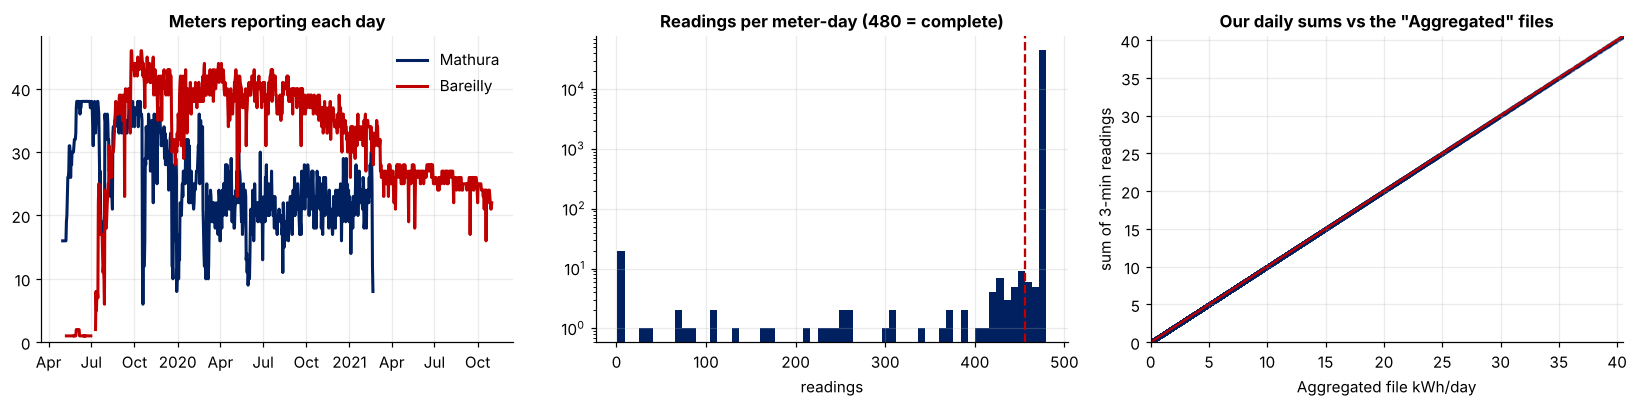

**Findings.** **84 meters** (38 in Mathura, 46 in Bareilly), **21.4 million readings**, median interval **180 s** (3 minutes).
When a meter reports on a day it is almost always complete (100% of reported days have 95% or more of their 480 readings), but meters are **missing whole days**: the typical meter has data on 82% of the days between its first and last reading (worst meter 36%), so the stream processor must tolerate silent meters.
Our daily sums agree with the supplied "Aggregated" files (correlation 1.000), which confirms `t_kWh` is energy per 3-minute interval.

In [14]:
dt_med = gaps.med_dt.median()
cov = daily.groupby(['city', 'date']).meter.nunique().unstack(0)
cmp_cols = ['t_kWh']
agg_files = {'Mathura': 'SM Cleaned Data MH Aggregated.csv', 'Bareilly': 'SM Cleaned Data BR Aggregated.csv'}
cmp = []
for city, fn in agg_files.items():
    a = pd.read_csv(DATA / fn, parse_dates=['Date']).rename(columns={'Date': 'date', 't_kWh': 'kwh_agg'})
    m = daily[daily.city == city].merge(a, on=['meter', 'date'], how='inner')
    cmp.append(m.assign(city=city))
cmp = pd.concat(cmp)
agg_corr = float(np.corrcoef(cmp.kwh, cmp.kwh_agg)[0, 1]); agg_med_rel = float(((cmp.kwh - cmp.kwh_agg).abs() / cmp.kwh_agg.clip(lower=.01)).median())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for city, col in (('Mathura', NAVY), ('Bareilly', RED)):
    ax[0].plot(cov.index, cov[city], color=col, lw=2, label=city)
ax[0].set_title('Meters reporting each day'); ax[0].set_ylim(0); ax[0].legend()
ax[1].hist(daily.n.clip(upper=480), 60, color=NAVY); ax[1].axvline(456, color=RED, ls='--'); ax[1].set_yscale('log')
ax[1].set_title('Readings per meter-day (480 = complete)'); ax[1].set_xlabel('readings')
ax[2].scatter(cmp.kwh_agg, cmp.kwh, s=3, alpha=.15, color=NAVY); lim = [0, np.nanpercentile(cmp.kwh_agg, 99.5)]
ax[2].plot(lim, lim, color=RED); ax[2].set_xlim(lim); ax[2].set_ylim(lim); ax[2].set_title('Our daily sums vs the "Aggregated" files')
ax[2].set_xlabel('Aggregated file kWh/day'); ax[2].set_ylabel('sum of 3-min readings')
fig.tight_layout(); save(fig, 'ceew_01_coverage')

city_stats = {c: dict(meters=int(g.meter.nunique()), first=str(g.date.min().date()), last=str(g.date.max().date()),
                      meter_days=int(len(g)), full_day_pct=float(g.full.mean() * 100)) for c, g in daily.groupby('city')}
cov_med = float(meters.coverage.median()); cov_min = float(meters.coverage.min())
SUMMARY['ceew'] = dict(cities=city_stats, meters=int(daily.meter.nunique()), readings=tot_rows, median_interval_s=float(dt_med),
                       full_day_pct=float(daily.full.mean() * 100), agg_corr=agg_corr,
                       coverage_median_pct=cov_med * 100, coverage_min_pct=cov_min * 100)
say(f'''**Findings.** **{daily.meter.nunique()} meters** ({city_stats['Mathura']['meters']} in Mathura, {city_stats['Bareilly']['meters']} in Bareilly), **{tot_rows / 1e6:.1f} million readings**, median interval **{dt_med:.0f} s** (3 minutes).
When a meter reports on a day it is almost always complete ({daily.full.mean():.0%} of reported days have 95% or more of their 480 readings), but meters are **missing whole days**: the typical meter has data on {cov_med:.0%} of the days between its first and last reading (worst meter {cov_min:.0%}), so the stream processor must tolerate silent meters.
Our daily sums agree with the supplied "Aggregated" files (correlation {agg_corr:.3f}), which confirms `t_kWh` is energy per 3-minute interval.''')

### 3.1 Consumption: level, daily rhythm and season

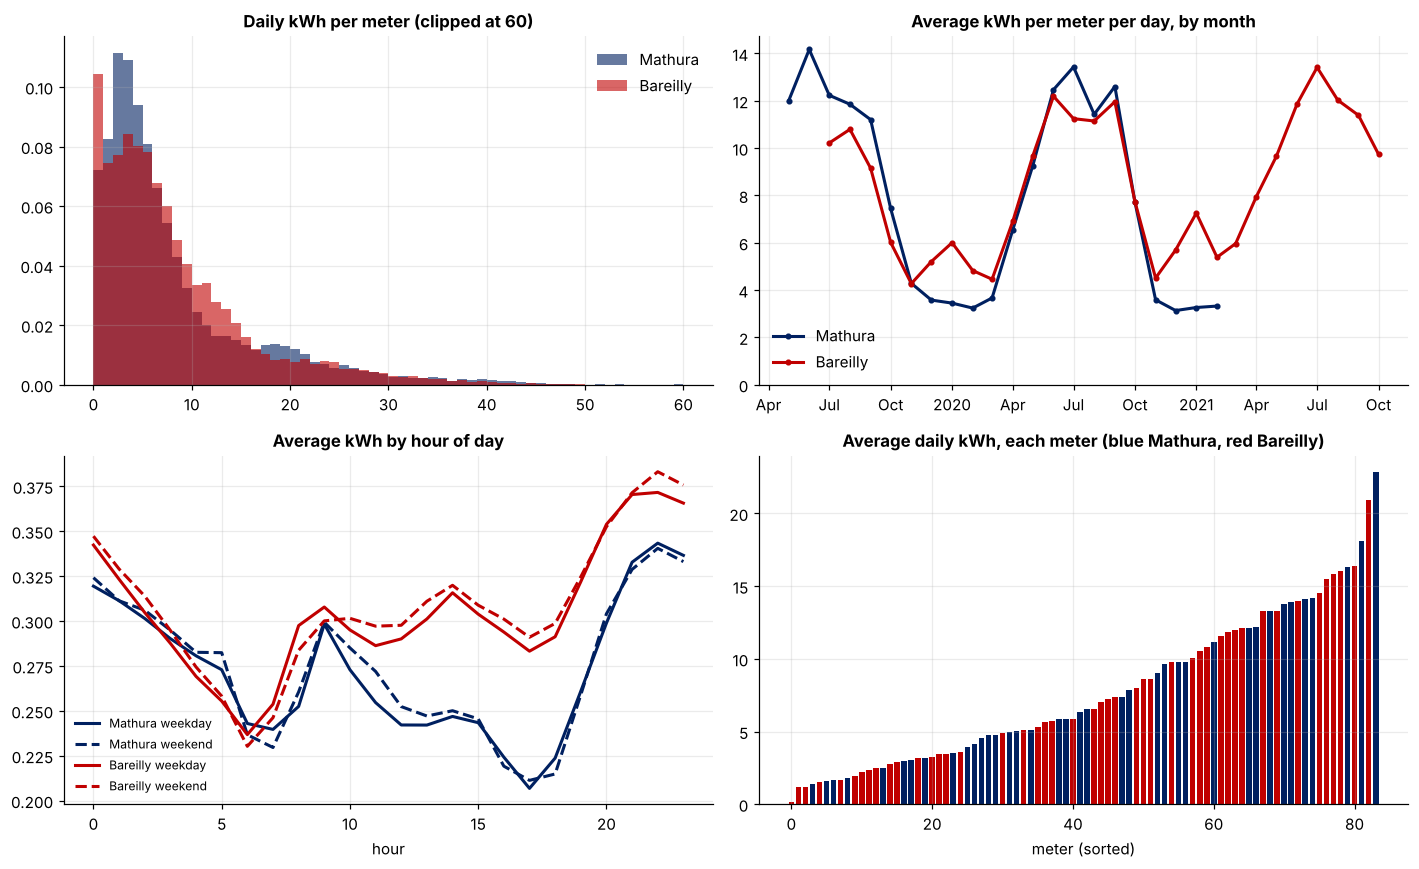

**Findings.** The average meter uses **7.7 kWh/day** (median 6.4), very unevenly: the heaviest meters use many times more than the lightest.
The monthly average peaks in **calendar month 6 in Mathura and 6 in Bareilly**, and the daily peak falls at hour 22 (Mathura) and 22 (Bareilly). Season and time of day shift usage a lot, so raw kWh cannot be compared across months without a peer baseline.

In [15]:
dfull = daily[daily.full].copy()
dfull['ym'] = dfull.date.dt.to_period('M').dt.to_timestamp()
mon = dfull.groupby(['city', 'ym']).agg(kwh=('kwh', 'mean'), meters=('meter', 'nunique')).reset_index()
mon = mon[mon.meters >= 5]
hp = hourly[~hourly.weekend].groupby(['city', 'hour']).kwh.mean().unstack(0)
hp_we = hourly[hourly.weekend].groupby(['city', 'hour']).kwh.mean().unstack(0)

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
a = ax[0, 0]
for city, col in (('Mathura', NAVY), ('Bareilly', RED)):
    a.hist(dfull[dfull.city == city].kwh.clip(upper=60), 60, alpha=.6, color=col, density=True, label=city)
a.set_title('Daily kWh per meter (clipped at 60)'); a.legend()
a = ax[0, 1]
for city, col in (('Mathura', NAVY), ('Bareilly', RED)):
    s = mon[mon.city == city]; a.plot(s.ym, s.kwh, color=col, lw=2, marker='o', ms=3, label=city)
a.set_title('Average kWh per meter per day, by month'); a.set_ylim(0); a.legend()
a = ax[1, 0]
for city, col in (('Mathura', NAVY), ('Bareilly', RED)):
    a.plot(hp.index, hp[city], color=col, lw=2, label=f'{city} weekday'); a.plot(hp_we.index, hp_we[city], color=col, lw=2, ls='--', label=f'{city} weekend')
a.set_title('Average kWh by hour of day'); a.set_xlabel('hour'); a.legend(fontsize=8)
a = ax[1, 1]
mk = meters.sort_values('mean_kwh')
a.bar(range(len(mk)), mk.mean_kwh, color=[NAVY if c == 'Mathura' else RED for c in mk.city]); a.set_title('Average daily kWh, each meter (blue Mathura, red Bareilly)'); a.set_xlabel('meter (sorted)')
fig.tight_layout(); save(fig, 'ceew_02_consumption')

seas_c = {}
for city in ('Mathura', 'Bareilly'):
    s = mon[mon.city == city].set_index('ym').kwh; sm = s.groupby(s.index.month).mean(); seas_c[city] = sm.reindex(range(1, 13))
    SEAS[f'{city} (India)'] = (sm / sm.mean()).reindex(range(1, 13)).values
peak_m = {c: int(seas_c[c].idxmax()) for c in seas_c}
SUMMARY['ceew'].update(mean_daily_kwh=float(meters.mean_kwh.mean()), median_daily_kwh=float(meters.mean_kwh.median()),
    month_labels=[d.strftime('%b %y') for d in sorted(mon.ym.unique())],
    monthly={c: {d.strftime('%b %y'): float(v) for d, v in zip(g.ym, g.kwh)} for c, g in mon.groupby('city')},
    hourly_weekday={c: [float(v) for v in hp[c].values] for c in hp.columns},
    peak_month=peak_m, evening_peak_hour={c: int(hp[c].idxmax()) for c in hp.columns})
say(f'''**Findings.** The average meter uses **{meters.mean_kwh.mean():.1f} kWh/day** (median {meters.mean_kwh.median():.1f}), very unevenly: the heaviest meters use many times more than the lightest.
The monthly average peaks in **calendar month {peak_m['Mathura']} in Mathura and {peak_m['Bareilly']} in Bareilly**, and the daily peak falls at hour {int(hp.Mathura.idxmax())} (Mathura) and {int(hp.Bareilly.idxmax())} (Bareilly). Season and time of day shift usage a lot, so raw kWh cannot be compared across months without a peer baseline.''')

### 3.2 Supply quality: power cuts and voltage

Only CEEW has voltage. A reading with **zero voltage** means the meter is logging but the supply is off (a power cut), and a low-voltage evening can look like "low consumption". Neither is theft, so the agent gets both as context.

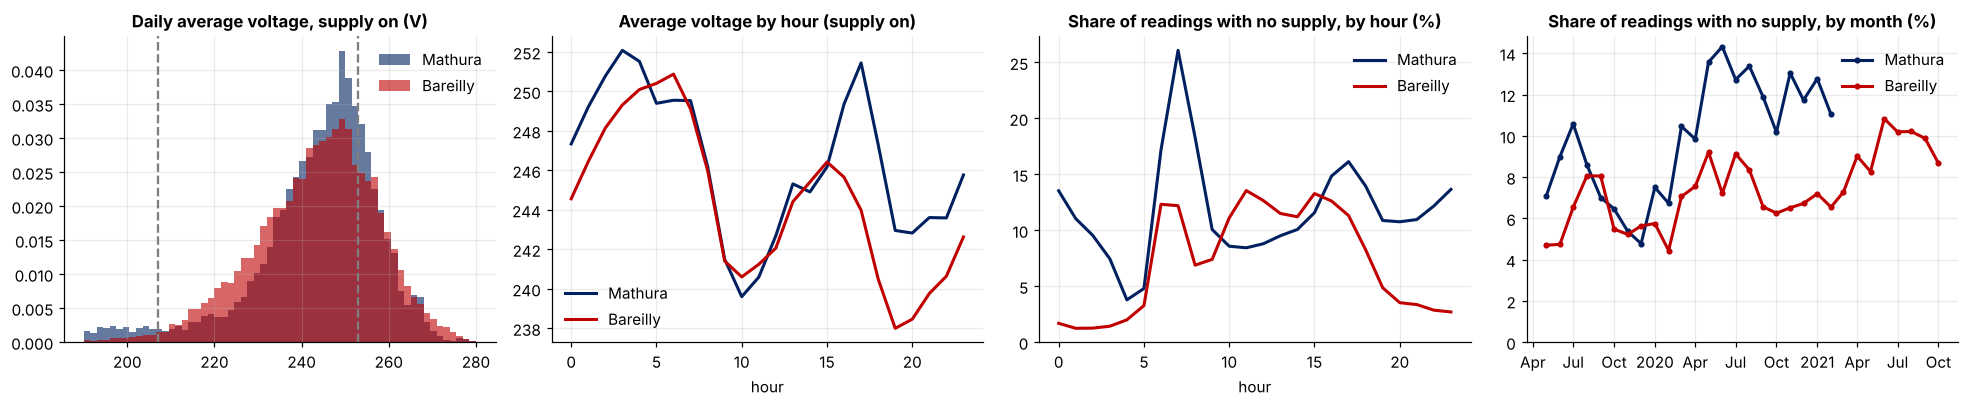

**Findings.** **8.2% of all readings have zero supply voltage** (Mathura 9.5%, Bareilly 7.4%), and **88% of meter-days contain at least one power cut** (median 87 minutes on those days). Cuts are most frequent at hour 7 (Mathura) and 11 (Bareilly).
While the supply is on, voltage averages **243 V**; 29% of readings are above 253 V and 4% below 207 V. Power cuts make consumption read zero, so a feature that treats "zero usage" as suspicious would flag innocent households. Zero kWh while the supply is on is still common (8.9% of supply-on readings, light-load intervals at 0.001 kWh resolution), so a single zero reading means little.
The agent therefore receives outage minutes and voltage as its "supply quality" tool, and the stream features must exclude outage periods.

In [16]:
n_all = daily.n.sum()
out_pct_city = {c: float(g.outage.sum() / g.n.sum() * 100) for c, g in daily.groupby('city')}
out_pct = float(daily.outage.sum() / n_all * 100)
days_out = float((daily.outage > 0).mean() * 100)
day_out_min = daily.loc[daily.outage > 0, 'outage'] * 3
on = daily.n - daily.outage
frac_low = float(daily.lowv.sum() / on.sum() * 100); frac_high = float(daily.highv.sum() / on.sum() * 100)
vo = dfull[dfull.v_mean.notna()]
vh = hourly.groupby(['city', 'hour']).v.mean().unstack(0)
oh = hourly.groupby(['city', 'hour']).out.mean().unstack(0) * 100
om = daily.assign(ym=daily.date.dt.to_period('M').dt.to_timestamp()).groupby(['city', 'ym']).agg(o=('outage', 'sum'), n=('n', 'sum')).reset_index()
om['pct'] = om.o / om.n * 100
zero_on = float(((daily.zero - daily.outage).clip(lower=0)).sum() / on.sum() * 100)

fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for city, col in (('Mathura', NAVY), ('Bareilly', RED)):
    ax[0].hist(vo[vo.city == city].v_mean, 60, range=(190, 280), alpha=.6, color=col, density=True, label=city)
ax[0].axvline(V_LOW, color=GREY, ls='--'); ax[0].axvline(V_HIGH, color=GREY, ls='--'); ax[0].set_title('Daily average voltage, supply on (V)'); ax[0].legend()
for city, col in (('Mathura', NAVY), ('Bareilly', RED)): ax[1].plot(vh.index, vh[city], color=col, lw=2, label=city)
ax[1].set_title('Average voltage by hour (supply on)'); ax[1].set_xlabel('hour'); ax[1].legend()
for city, col in (('Mathura', NAVY), ('Bareilly', RED)): ax[2].plot(oh.index, oh[city], color=col, lw=2, label=city)
ax[2].set_title('Share of readings with no supply, by hour (%)'); ax[2].set_xlabel('hour'); ax[2].set_ylim(0); ax[2].legend()
for city, col in (('Mathura', NAVY), ('Bareilly', RED)):
    s = om[om.city == city]; ax[3].plot(s.ym, s.pct, color=col, lw=2, marker='o', ms=3, label=city)
ax[3].set_title('Share of readings with no supply, by month (%)'); ax[3].set_ylim(0); ax[3].legend()
fig.tight_layout(); save(fig, 'ceew_03_voltage')
SUMMARY['ceew'].update(voltage_mean=float(vo.v_mean.mean()), voltage_p5=float(vo.v_mean.quantile(.05)), voltage_p95=float(vo.v_mean.quantile(.95)),
                       pct_readings_below_207=frac_low, pct_readings_above_253=frac_high, outage_pct=out_pct, outage_pct_city=out_pct_city,
                       pct_days_with_outage=days_out, median_outage_minutes_on_outage_days=float(day_out_min.median()),
                       zero_kwh_while_powered_pct=zero_on, peak_outage_hour={c: int(oh[c].idxmax()) for c in oh.columns},
                       outage_hourly={c: [float(v) for v in oh[c].values] for c in oh.columns},
                       outage_month_labels=[d.strftime('%b %y') for d in sorted(om.ym.unique())],
                       outage_monthly={c: {d.strftime('%b %y'): float(v) for d, v in zip(g.ym, g.pct)} for c, g in om.groupby('city')})
say(f'''**Findings.** **{out_pct:.1f}% of all readings have zero supply voltage** (Mathura {out_pct_city['Mathura']:.1f}%, Bareilly {out_pct_city['Bareilly']:.1f}%), and **{days_out:.0f}% of meter-days contain at least one power cut** (median {day_out_min.median():.0f} minutes on those days). Cuts are most frequent at hour {int(oh.Mathura.idxmax())} (Mathura) and {int(oh.Bareilly.idxmax())} (Bareilly).
While the supply is on, voltage averages **{vo.v_mean.mean():.0f} V**; {frac_high:.0f}% of readings are above {V_HIGH} V and {frac_low:.0f}% below {V_LOW} V. Power cuts make consumption read zero, so a feature that treats "zero usage" as suspicious would flag innocent households. Zero kWh while the supply is on is still common ({zero_on:.1f}% of supply-on readings, light-load intervals at 0.001 kWh resolution), so a single zero reading means little.
The agent therefore receives outage minutes and voltage as its "supply quality" tool, and the stream features must exclude outage periods.''')

### 3.3 Weather without a thermometer: do neighbours share the weather effect?

CEEW has no temperature column. If weather drives usage, **all meters in a city should rise and fall together**. If so, dividing a household by its peer group's median removes the weather effect (and the season, holidays and outages) without needing weather data.

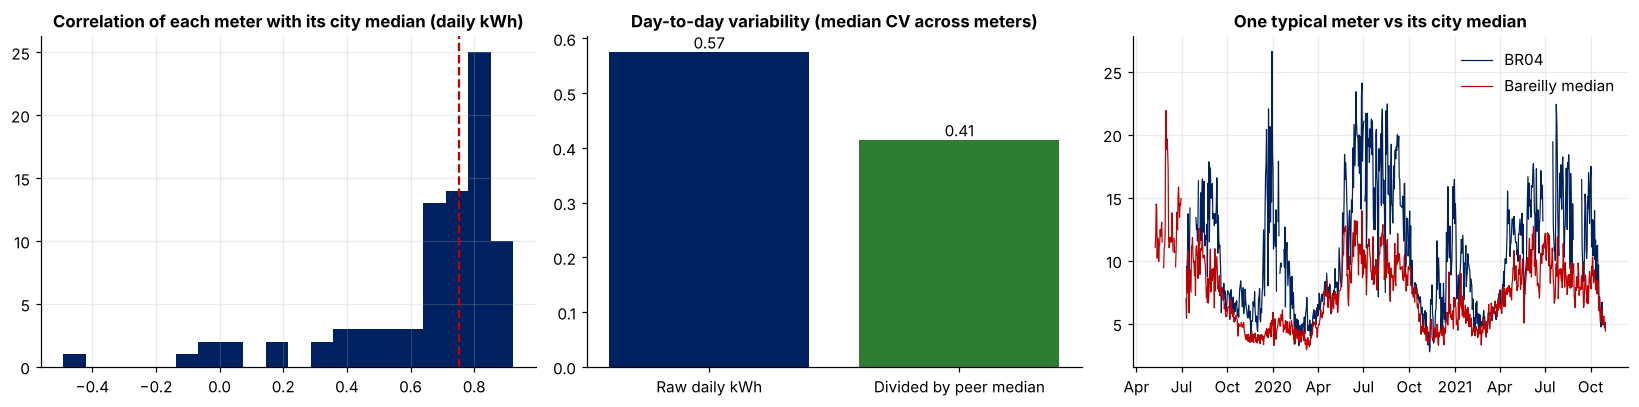

**Findings.** The typical meter moves with its city: median correlation **0.75**. Dividing by the peer median cuts day-to-day variability from **0.57 to 0.41** (28% lower), so seasonal and weather swings largely cancel. This supports using peer-relative features instead of raw kWh.

In [17]:
piv = dfull.pivot_table(index='date', columns='meter', values='kwh')
city_of = meters.set_index('meter').city
rows = []
for city in ('Mathura', 'Bareilly'):
    cols_ = [m for m in piv.columns if city_of.get(m) == city]
    P = piv[cols_]; P = P[P.count(axis=1) >= 8]
    med_city = P.median(axis=1)
    for m in cols_:
        s = P[m].dropna()
        if len(s) < 90: continue
        rel = s / med_city.reindex(s.index)
        rows.append(dict(city=city, meter=m, corr_with_peers=float(np.corrcoef(s, med_city.reindex(s.index))[0, 1]),
                         cv_raw=float(s.std() / s.mean()), cv_relative=float(rel.replace([np.inf, -np.inf], np.nan).std() / rel.replace([np.inf, -np.inf], np.nan).mean())))
pe = pd.DataFrame(rows)
med_corr, cv_raw, cv_rel = pe.corr_with_peers.median(), pe.cv_raw.median(), pe.cv_relative.median()

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(pe.corr_with_peers, 20, color=NAVY); ax[0].axvline(med_corr, color=RED, ls='--'); ax[0].set_title('Correlation of each meter with its city median (daily kWh)')
ax[1].bar(['Raw daily kWh', 'Divided by peer median'], [cv_raw, cv_rel], color=[NAVY, GREEN])
for i, v in enumerate([cv_raw, cv_rel]): ax[1].text(i, v, f'{v:.2f}', ha='center', va='bottom')
ax[1].set_title('Day-to-day variability (median CV across meters)'); ax[1].grid(False)
ex = pe.sort_values('corr_with_peers').iloc[len(pe) // 2]; mex = ex.meter; cex = ex.city
cols_ = [m for m in piv.columns if city_of.get(m) == cex]; mc = piv[cols_].median(axis=1)
ax[2].plot(piv.index, piv[mex], color=NAVY, lw=.8, label=f'{mex}'); ax[2].plot(mc.index, mc, color=RED, lw=.8, label=f'{cex} median'); ax[2].set_title('One typical meter vs its city median'); ax[2].legend()
fig.tight_layout(); save(fig, 'ceew_04_peers_weather')
SUMMARY['ceew'].update(peer_corr_median=float(med_corr), cv_raw=float(cv_raw), cv_relative=float(cv_rel), cv_reduction_pct=float((1 - cv_rel / cv_raw) * 100))
say(f'''**Findings.** The typical meter moves with its city: median correlation **{med_corr:.2f}**. Dividing by the peer median cuts day-to-day variability from **{cv_raw:.2f} to {cv_rel:.2f}** ({(1 - cv_rel / cv_raw):.0%} lower), so seasonal and weather swings largely cancel. This supports using peer-relative features instead of raw kWh.''')

### 3.4 Behavioural peer groups (no location available)

The files have no addresses, so "neighbours" are defined by **usage shape**: meters whose normalised hourly profile looks alike are grouped (k-means) using only an initial period.

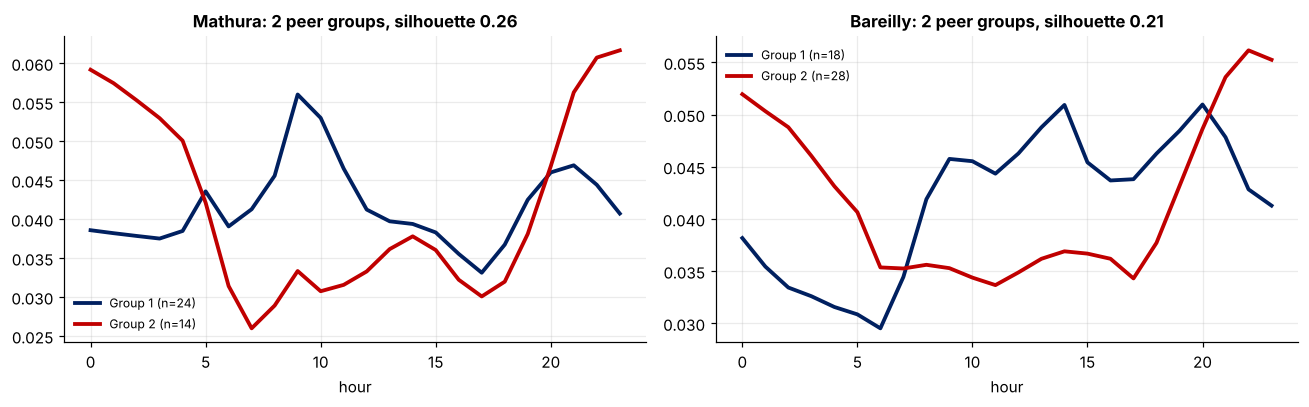

**Findings.** Clustering all 84 meters by daily shape into 2 groups matches the city labels with 55% purity. Shape clusters cut across the two cities (purity only 55%), so households in both cities share similar daily routines and peer groups can be built from shape, not from city.
Within each city, the best split is 2 groups in Mathura (sizes [24, 14], silhouette 0.26) and 2 in Bareilly (sizes [18, 28], silhouette 0.21).
Silhouettes below about 0.5 mean households form a continuum rather than tight clusters, so peer groups are used as a **comparison baseline**, not as hard categories. With only 84 meters, a peer median is taken over groups of roughly 21 meters.

In [18]:
prof = hourly[~hourly.weekend].pivot_table(index='meter', columns='hour', values='kwh').dropna()
prof_n = prof.div(prof.sum(axis=1), axis=0)
cityv = meters.set_index('meter').city.reindex(prof_n.index)
try:
    from sklearn.cluster import KMeans
    from sklearn.metrics import silhouette_score
    k_all = KMeans(2, n_init=10, random_state=0).fit_predict(prof_n)
    ct_ = pd.crosstab(k_all, cityv); purity = float(ct_.max(axis=1).sum() / ct_.values.sum())
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8)); res_peer = {}
    cols_k = [NAVY, RED, GREEN, GOLD]
    for a_, city in zip(ax, ('Mathura', 'Bareilly')):
        P = prof_n[cityv == city]
        sil = {k: silhouette_score(P, KMeans(k, n_init=10, random_state=0).fit_predict(P)) for k in (2, 3, 4)}
        kb = max(sil, key=sil.get); km = KMeans(kb, n_init=10, random_state=0).fit(P)
        for k in range(kb):
            a_.plot(P.columns, km.cluster_centers_[k], color=cols_k[k], lw=2.5, label=f'Group {k + 1} (n={int((km.labels_ == k).sum())})')
        a_.set_title(f'{city}: {kb} peer groups, silhouette {sil[kb]:.2f}'); a_.set_xlabel('hour'); a_.legend(fontsize=8)
        res_peer[city] = dict(k=int(kb), silhouette=float(sil[kb]), sizes=[int((km.labels_ == k).sum()) for k in range(kb)], meters=int(len(P)))
    fig.tight_layout(); save(fig, 'ceew_05_peer_groups')
    SUMMARY['ceew'].update(peer_groups=res_peer, peer_city_purity=purity)
    cityline = ('Shape alone separates the two cities almost perfectly, so city is a natural first peer boundary.' if purity > .8 else
                'Shape clusters cut across the two cities (purity only %.0f%%), so households in both cities share similar daily routines and peer groups can be built from shape, not from city.' % (purity * 100))
    say(f'''**Findings.** Clustering all {len(prof_n)} meters by daily shape into 2 groups matches the city labels with {purity:.0%} purity. {cityline}
Within each city, the best split is {res_peer['Mathura']['k']} groups in Mathura (sizes {res_peer['Mathura']['sizes']}, silhouette {res_peer['Mathura']['silhouette']:.2f}) and {res_peer['Bareilly']['k']} in Bareilly (sizes {res_peer['Bareilly']['sizes']}, silhouette {res_peer['Bareilly']['silhouette']:.2f}).
Silhouettes below about 0.5 mean households form a continuum rather than tight clusters, so peer groups are used as a **comparison baseline**, not as hard categories. With only {len(prof_n)} meters, a peer median is taken over groups of roughly {int(np.mean([s for r in res_peer.values() for s in r['sizes']]))} meters.''')
except ImportError:
    print('scikit-learn not installed')

### 3.5 Theft injection: what Mode B will look like

Standard attack types from Jokar et al. (2016) are applied to a real meter from a chosen start time, which gives the **exact ground-truth start** that real datasets lack. Below, one meter's half-hourly kWh with each attack starting on day 3.

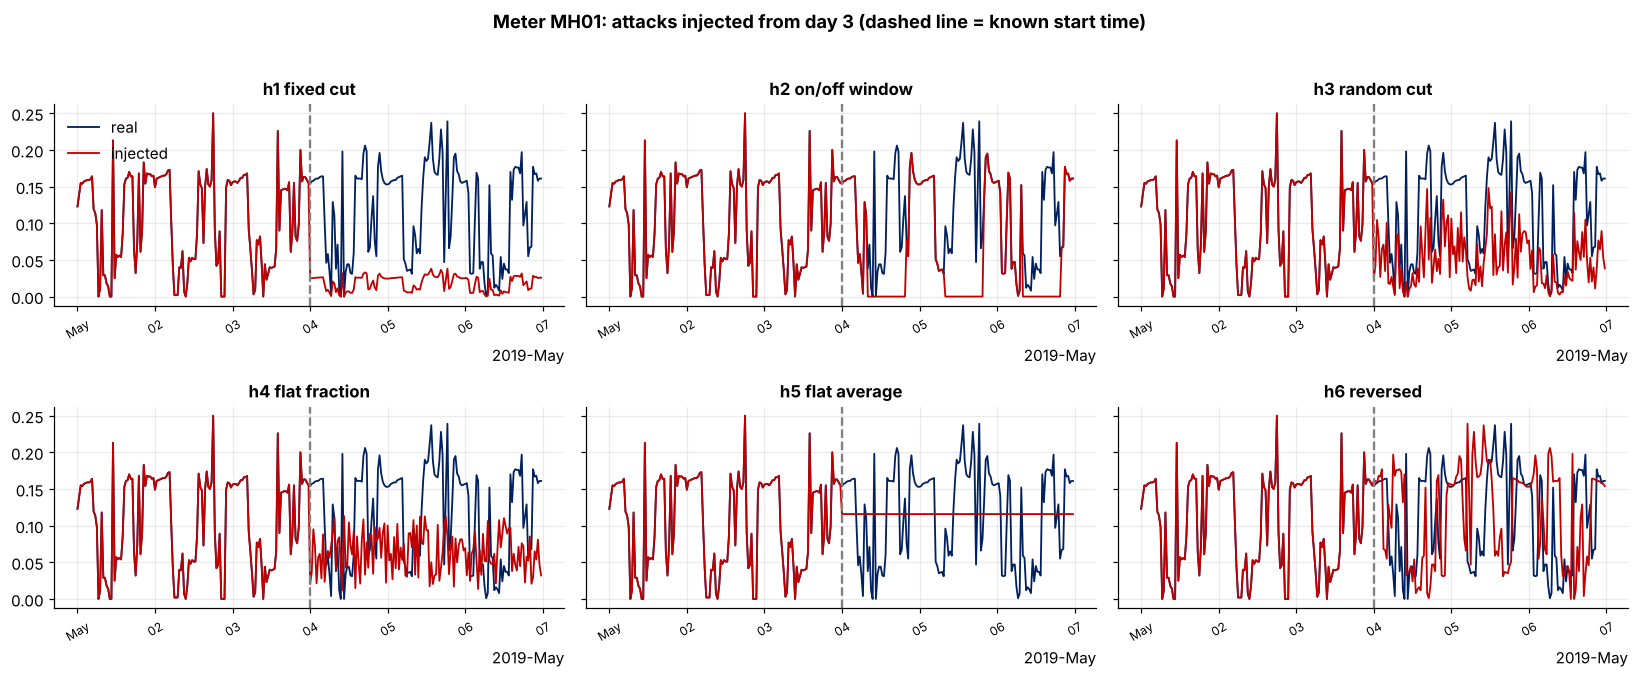

In [19]:
f19 = DATA / 'CEEW - Smart meter data Mathura 2019.csv'
raw = pd.read_csv(f19, nrows=95000, parse_dates=['x_Timestamp'])      # the file is sorted by meter: the first meter comes first
m0 = raw.meter.iloc[0]; raw = raw[raw.meter == m0]
hh_ser = raw.set_index('x_Timestamp').t_kWh.resample('30min').sum()
hh_ser = hh_ser.iloc[:48 * 6]
rng = np.random.default_rng(7)
start = 48 * 3

def attack(x, kind, start, rng):
    y = x.copy(); seg = x[start:]
    if kind == 'h1 fixed cut':       y[start:] = seg * rng.uniform(.1, .8)
    elif kind == 'h2 on/off window':  idx = (np.arange(start, len(x)) % 48); y[start:] = np.where((idx >= 16) & (idx < 40), 0, seg)
    elif kind == 'h3 random cut':    y[start:] = seg * rng.uniform(.1, .8, len(seg))
    elif kind == 'h4 flat fraction': y[start:] = seg.mean() * rng.uniform(.1, 1, len(seg))
    elif kind == 'h5 flat average':  y[start:] = seg.mean()
    elif kind == 'h6 reversed':      y[start:] = seg[::-1]
    return y

kinds = ['h1 fixed cut', 'h2 on/off window', 'h3 random cut', 'h4 flat fraction', 'h5 flat average', 'h6 reversed']
x = hh_ser.values.astype(float)
fig, ax = plt.subplots(2, 3, figsize=(15, 6), sharey=True)
for a, kd in zip(ax.ravel(), kinds):
    a.plot(hh_ser.index, x, color=NAVY, lw=1.2, label='real'); a.plot(hh_ser.index, attack(x, kd, start, np.random.default_rng(3)), color=RED, lw=1.2, label='injected')
    a.axvline(hh_ser.index[start], color=GREY, ls='--'); a.set_title(kd); a.tick_params(axis='x', labelrotation=30, labelsize=8)
ax[0, 0].legend(); fig.suptitle(f'Meter {m0}: attacks injected from day 3 (dashed line = known start time)', y=1.02, fontweight='bold')
fig.tight_layout(); save(fig, 'ceew_06_injection_demo')
SUMMARY['ceew']['injection_attack_types'] = kinds

---
# 4. Low Carbon London (UK Power Networks)

Half-hourly readings for about 5,500 London households, split across 168 files of roughly 1 million rows each. No theft labels. We use it for **scale** (can the pipeline keep up?) and as a **weather contrast** (cold-climate heating peak vs Indian summer cooling peak).

In [20]:
# PREP-DEFS
lcl_dir = DATA / 'Small LCL Data'
def lcl_list():
    fs = sorted(lcl_dir.glob('LCL-June2015v2_*.csv'), key=lambda p: int(p.stem.split('_')[-1]))
    return fs[:12] if QUICK else fs

def lcl_one(p):
    cache = CACHE / f'lcl_{p.stem}.pkl'
    if cache.exists():
        return pd.read_pickle(cache)
    df = pd.read_csv(p, header=0, names=['id', 'tariff', 'dt', 'kwh'], dtype={'id': 'category', 'tariff': 'category', 'dt': 'string', 'kwh': 'string'})
    df['kwh'] = pd.to_numeric(df.kwh.str.strip(), errors='coerce').astype('float32')
    df['ts'] = pd.to_datetime(df.dt.str.slice(0, 19), format='%Y-%m-%d %H:%M:%S')
    df['date'] = df.ts.dt.normalize(); df['slot'] = (df.ts.dt.hour * 2 + df.ts.dt.minute // 30).astype('int8')
    df['na'] = df.kwh.isna()
    d = df.groupby(['id', 'date'], observed=True).agg(kwh=('kwh', 'sum'), n=('kwh', 'size'), na=('na', 'sum')).reset_index()
    d['id'] = d['id'].astype(str)
    tar = df.groupby('id', observed=True).tariff.first().astype(str); tar.index = tar.index.astype(str)
    prof = df.groupby(['tariff', 'slot'], observed=True).kwh.agg(['sum', 'count']).reset_index()
    prof['tariff'] = prof.tariff.astype(str)
    out = (d, tar, prof, len(df), int(df.na.sum()))
    pd.to_pickle(out, cache)
    return out

In [21]:
cache_l = CACHE / ('lcl_quick.pkl' if QUICK else 'lcl_all.pkl')
if cache_l.exists():
    L = pd.read_pickle(cache_l)
else:
    lcl_files = lcl_list()
    assert lcl_files, f"No London files found in {lcl_dir}"
    t0 = time.time(); ds, ts_, ps, nr, nn = [], [], [], 0, 0
    for i, p in enumerate(lcl_files):
        d, tar, prof, r, n_na = lcl_one(p); ds.append(d); ts_.append(tar); ps.append(prof); nr += r; nn += n_na
        if (i + 1) % 20 == 0 or i + 1 == len(lcl_files): print(f'{i + 1}/{len(lcl_files)} files, {time.time() - t0:.0f}s')
    daily_l = pd.concat(ds, ignore_index=True)
    daily_l['id'] = daily_l['id'].astype('category')
    daily_l['kwh'] = daily_l['kwh'].astype('float32'); daily_l['n'] = daily_l['n'].astype('int16'); daily_l['na'] = daily_l['na'].astype('int16')
    L = dict(daily=daily_l, tariff=pd.concat(ts_), prof=pd.concat(ps), rows=nr, nulls=nn, files=len(lcl_files))
    pd.to_pickle(L, cache_l)

ld, ltar = L['daily'], L['tariff'][~L['tariff'].index.duplicated()]
ld['id'] = ld['id'].astype(str)
ld['tariff'] = ld.id.map(ltar)
ld['full'] = ld.n == 48
n_hh = ld.id.nunique()
hist_days = ld.groupby('id').date.nunique()
print(f"{L['rows']:,} rows | {n_hh:,} households | {L['nulls']:,} null readings ({L['nulls'] / L['rows']:.3%})")
SUMMARY['lcl'] = dict(files=int(L['files']), households=int(n_hh), rows=int(L['rows']), null_pct=float(L['nulls'] / L['rows'] * 100),
                      first=str(ld.date.min().date()), last=str(ld.date.max().date()), tariff_counts={k: int(v) for k, v in ltar.value_counts().items()},
                      median_history_days=float(hist_days.median()), quick_mode=bool(QUICK))
ltar.value_counts().rename('households').to_frame()

167,932,474 rows | 5,566 households | 5,560 null readings (0.003%)


,households
tariff,
Std,4443
ToU,1123


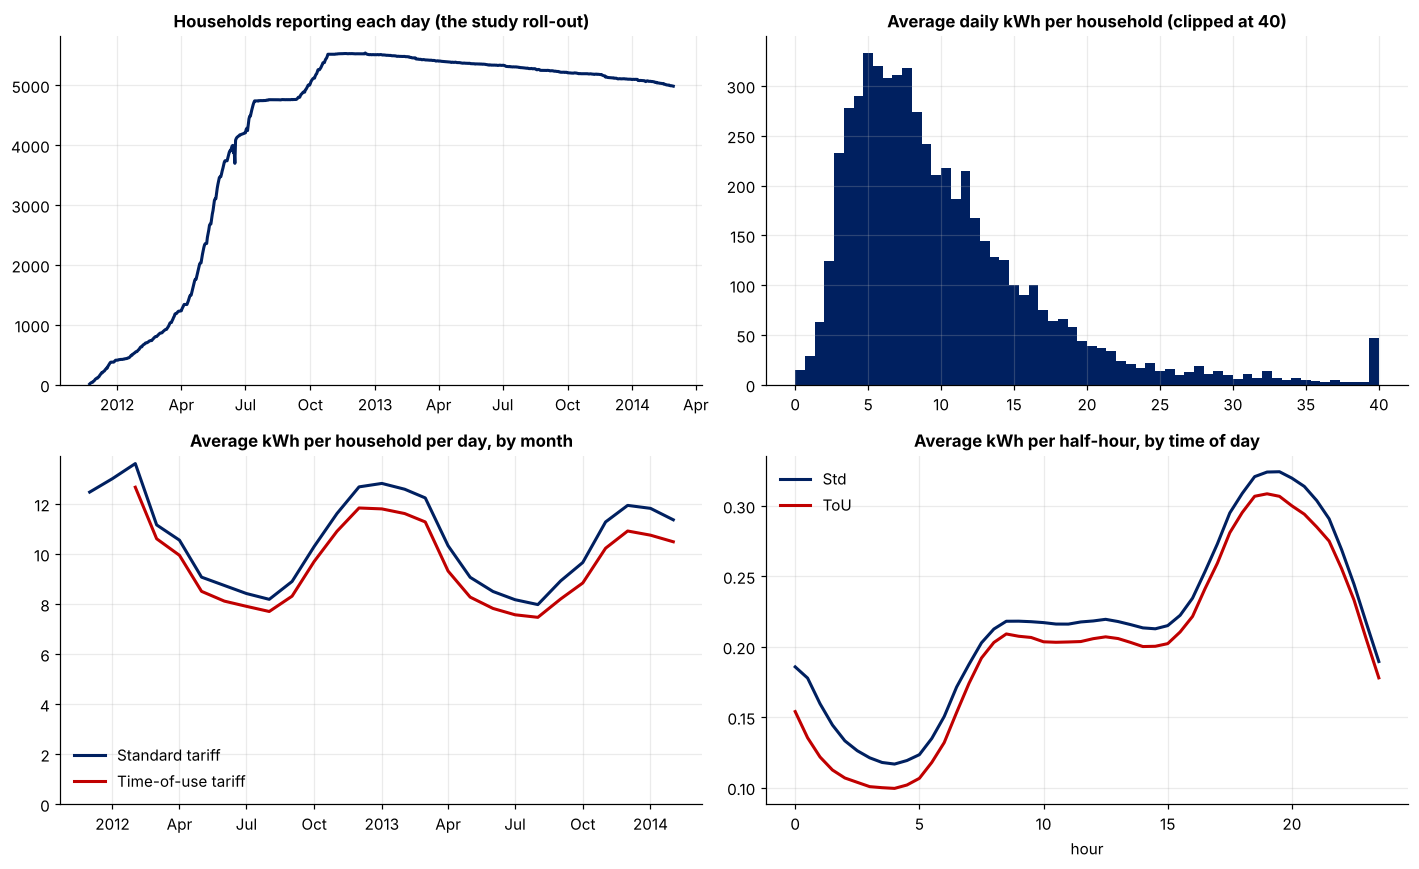

**Findings.** **5,566 households**, **168 million half-hourly readings**, 2011-11-23 to 2014-02-28, with only 0.003% null readings. Households join gradually (median history 651 days), so a streaming system must handle meters with short histories.
The average household uses **10.2 kWh/day** and usage peaks in **calendar month 1** (winter heating), the opposite pattern to the Indian meters.
**Scale check:** at one reading per half-hour, 5,541 live households produce about **3 messages/second**; replaying at 1,000x speed gives about **3,078 messages/second**, a realistic load for Redpanda and Flink.

In [22]:
lf = ld[ld.full & (ld.kwh >= 0)]
active = ld.groupby('date').id.nunique()
lm = lf.assign(ym=lf.date.dt.to_period('M').dt.to_timestamp()).groupby(['tariff', 'ym']).agg(kwh=('kwh', 'mean'), hh=('id', 'nunique')).reset_index()
lm = lm[lm.hh >= 100]
pr = L['prof'].groupby(['tariff', 'slot'])[['sum', 'count']].sum().reset_index(); pr['mean'] = pr['sum'] / pr['count']
hh_mean = lf.groupby('id').kwh.mean()

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
a = ax[0, 0]; a.plot(active.index, active.values, color=NAVY, lw=2); a.set_title('Households reporting each day (the study roll-out)'); a.set_ylim(0)
a = ax[0, 1]; a.hist(hh_mean.clip(upper=40), 60, color=NAVY); a.set_title('Average daily kWh per household (clipped at 40)')
a = ax[1, 0]
for t, col in (('Std', NAVY), ('ToU', RED)):
    s = lm[lm.tariff == t]
    if len(s): a.plot(s.ym, s.kwh, color=col, lw=2, label={'Std': 'Standard tariff', 'ToU': 'Time-of-use tariff'}[t])
a.set_title('Average kWh per household per day, by month'); a.set_ylim(0); a.legend()
a = ax[1, 1]
for t, col in (('Std', NAVY), ('ToU', RED)):
    s = pr[pr.tariff == t]
    if len(s): a.plot(s.slot / 2, s['mean'], color=col, lw=2, label=t)
a.set_title('Average kWh per half-hour, by time of day'); a.set_xlabel('hour'); a.legend()
fig.tight_layout(); save(fig, 'lcl_01_overview')

monL = lf.groupby(lf.date.dt.to_period('M').dt.to_timestamp()).agg(kwh=('kwh', 'mean'), hh=('id', 'nunique'))
monL = monL[monL.hh >= 100]
sL = monL.kwh.groupby(monL.index.month).mean().reindex(range(1, 13)); SEAS['London (UK)'] = (sL / sL.mean()).values
peak_l = int(sL.idxmax())
rate_msgs = n_hh / 1800
SUMMARY['lcl'].update(mean_daily_kwh=float(hh_mean.mean()), median_daily_kwh=float(hh_mean.median()), peak_month=peak_l,
    active_peak=int(active.max()), month_labels=[d.strftime('%b %y') for d in monL.index], monthly_kwh=[float(v) for v in monL.kwh],
    profile_slots=[float(v) for v in pr[pr.tariff == pr.tariff.iloc[0]]['mean']],
    msgs_per_sec_realtime=float(active.max() / 1800), msgs_per_sec_replay_1000x=float(active.max() / 1800 * 1000))
say(f'''**Findings.** **{n_hh:,} households**, **{L['rows'] / 1e6:.0f} million half-hourly readings**, {ld.date.min().date()} to {ld.date.max().date()}, with only {L['nulls'] / L['rows']:.3%} null readings. Households join gradually (median history {hist_days.median():.0f} days), so a streaming system must handle meters with short histories.
The average household uses **{hh_mean.mean():.1f} kWh/day** and usage peaks in **calendar month {peak_l}** (winter heating), the opposite pattern to the Indian meters.
**Scale check:** at one reading per half-hour, {active.max():,} live households produce about **{active.max() / 1800:.0f} messages/second**; replaying at 1,000x speed gives about **{active.max() / 1800 * 1000:,.0f} messages/second**, a realistic load for Redpanda and Flink.''')

---
# 5. Putting it together

### 5.1 Seasonality: why weather has to be handled
Each line is a dataset's average usage by calendar month relative to its own annual mean.

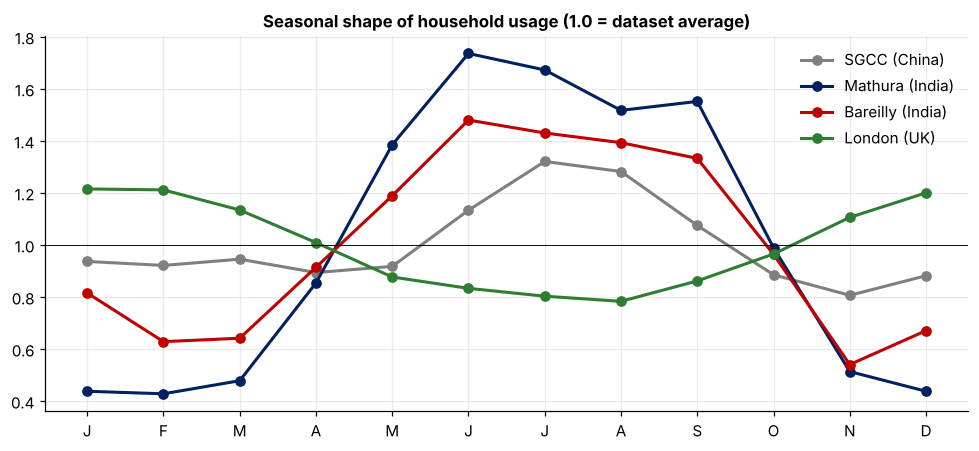

**Findings.** Seasonal swing (peak minus trough, as a share of the average): **SGCC (China)** 51%, **Mathura (India)** 131%, **Bareilly (India)** 94%, **London (UK)** 43%. Peaks fall in different months across datasets, so a single seasonal rule cannot work everywhere; comparing each meter with its own peer group is the common fix.

In [23]:
fig, ax = plt.subplots(figsize=(9, 4.2))
cols_s = {'SGCC (China)': GREY, 'Mathura (India)': NAVY, 'Bareilly (India)': RED, 'London (UK)': GREEN}
for k, v in SEAS.items():
    ax.plot(range(1, 13), v, marker='o', lw=2, color=cols_s.get(k), label=k)
ax.axhline(1, color='k', lw=.6); ax.set_xticks(range(1, 13)); ax.set_xticklabels(list('JFMAMJJASOND'))
ax.set_title('Seasonal shape of household usage (1.0 = dataset average)'); ax.legend()
fig.tight_layout(); save(fig, 'summary_01_seasonality')
SUMMARY['seasonality'] = {k: [float(x) for x in v] for k, v in SEAS.items()}
amp = {k: float(np.nanmax(v) - np.nanmin(v)) for k, v in SEAS.items()}
say('**Findings.** Seasonal swing (peak minus trough, as a share of the average): ' + ', '.join(f'**{k}** {v:.0%}' for k, v in amp.items()) +
    '. Peaks fall in different months across datasets, so a single seasonal rule cannot work everywhere; comparing each meter with its own peer group is the common fix.')

### 5.2 Which dataset does what

In [24]:
S = SUMMARY
role = pd.DataFrame([
    ['SGCC', 'China', f"{S['sgcc']['consumers']:,} consumers", f"{S['sgcc']['thieves']:,} ({S['sgcc']['theft_pct']:.1f}%) real, per consumer", 'daily', f"{S['sgcc']['first']} to {S['sgcc']['last']}", 'Mode A: accuracy', f"no theft dates; {S['sgcc']['missing_pct']:.0f}% missing; bad values"],
    ['STEG', 'Tunisia', f"{S['steg']['clients_train']:,} clients", f"{S['steg']['fraud']:,} ({S['steg']['fraud_pct']:.1f}%) real, per client", f"billing, ~{S['steg']['median_gap_days']:.0f}-day gaps", f"{S['steg']['invoice_first'][:4]} to {S['steg']['invoice_last'][:4]}", 'Mode A: second accuracy set', 'too sparse for real-time; mixed gas/electric'],
    ['CEEW', 'India', f"{S['ceew']['meters']} meters", 'none (inject theft)', '3 minutes', f"{min(c['first'] for c in S['ceew']['cities'].values())} to {max(c['last'] for c in S['ceew']['cities'].values())}", 'Mode B: detection speed', 'small; outages; no weather column'],
    ['London', 'UK', f"{S['lcl']['households']:,} households", 'none (inject theft)', '30 minutes', f"{S['lcl']['first']} to {S['lcl']['last']}", 'Mode B: scale test', 'different climate and tariffs'],
], columns=['Dataset', 'Country', 'Entities', 'Real theft labels', 'Resolution', 'Period', 'Role', 'Main caveats'])
pd.set_option('display.max_colwidth', 80); role

,Dataset,Country,Entities,Real theft labels,Resolution,Period,Role,Main caveats
0,SGCC,China,"42,372 consumers","3,615 (8.5%) real, per consumer",daily,2014-01-01 to 2016-10-31,Mode A: accuracy,no theft dates; 26% missing; bad values
1,STEG,Tunisia,"135,493 clients","7,566 (5.6%) real, per client","billing, ~121-day gaps",1977 to 2019,Mode A: second accuracy set,too sparse for real-time; mixed gas/electric
2,CEEW,India,84 meters,none (inject theft),3 minutes,2019-05-01 to 2021-10-31,Mode B: detection speed,small; outages; no weather column
3,London,UK,"5,566 households",none (inject theft),30 minutes,2011-11-23 to 2014-02-28,Mode B: scale test,different climate and tariffs


### 5.3 Decisions the EDA supports

1. **Evaluate in two modes and never pool them.** Real labels (SGCC, STEG) answer *who*; injected theft (CEEW, London) answers *how fast*.
2. **Do not rely on consumption drops.** On SGCC the largest-monthly-drop feature is a coin toss; level, growth and regularity carry the signal.
3. **Keep gaps as a feature, but tolerate them.** Thieves have more missing readings in SGCC, and Indian meters have outages; the stream processor needs event-time handling and per-meter state.
4. **Use peer-relative features** instead of weather data: Indian meters co-move strongly, and dividing by the peer median removes most seasonal swing.
5. **Pass voltage to the agent as context** (CEEW only): sags are a competing explanation for low usage.
6. **Treat STEG as accuracy-only**: invoices are months apart.
7. **Split by consumer before any scaling, imputation or oversampling** to avoid leakage.

In [25]:
class _Enc(json.JSONEncoder):
    def default(self, o):
        if isinstance(o, (np.integer,)): return int(o)
        if isinstance(o, (np.floating,)): return float(o)
        if isinstance(o, (np.ndarray,)): return o.tolist()
        return str(o)
(OUT / 'summary.json').write_text(json.dumps(SUMMARY, indent=1, cls=_Enc))
print('Saved', OUT / 'summary.json', 'and', len(list(OUT.glob('*.png'))), 'figures in', OUT)

Saved eda_outputs/summary.json and 15 figures in eda_outputs
